# Prot2GO: Enhancing Protein Function Annotation with Hierarchical Graph Neural Networks

Author: Cleverson M., PhD

## Setting the Environment

### Importing Modules

In [1]:
# Importing modules

import os
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import warnings
import pickle
import requests
from concurrent.futures import ThreadPoolExecutor
import string
import re
import random

import matplotlib.pyplot as plt
import seaborn as sns

from Bio import SeqIO
from obonet import read_obo
import networkx as nx

import spacy
from spacy.lang.en.stop_words import STOP_WORDS

import torch
import torch.nn.functional as F
from torch.nn import BatchNorm1d
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torch.cuda.amp import GradScaler, autocast

from torch_geometric.utils import structured_negative_sampling_feasible, degree
from torch_geometric.data import Data, HeteroData
from torch_geometric.nn import GATConv, Linear
import torch_geometric.transforms as T

from transformers import BertTokenizer, BertModel
from sentence_transformers import SentenceTransformer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    roc_auc_score,
    ConfusionMatrixDisplay,
    classification_report,
)

# Disable warnings
warnings.filterwarnings("ignore")

# Set CUDA
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.environ["TORCH"] = torch.__version__

# Check PyTorch and CUDA
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA version: {torch.version.cuda}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Device: {device}")

PyTorch version: 2.3.0
CUDA version: 12.1
CUDA available: True
Device: cuda


### Creating Prot2GO Folders

In [2]:
# root path
root = Path("/home/clever/datascience/projects/prot2go")

# data path
data_folder = root / "data"

# results path
results_folder = root / "results"
results_folder.mkdir(parents=True, exist_ok=True)

# List of species
species = ["human", "yeast", "ecoli", "mouse", "elegans", "droso", "benchmark"]

# Base directories
base_directories = [
    "eda",  # EDA of protein and PPI data
    "metadata",  # protein and PPI metadata
    "datasets",  # protein embeddings and PPI torch datasets
]

# Create the directory structure
for specie in species:
    for base_dir in base_directories:
        folder_path = results_folder / specie / base_dir
        folder_path.mkdir(parents=True, exist_ok=True)

# Create directory to save GO
go_folder = results_folder / "go"
go_folder.mkdir(parents=True, exist_ok=True)

# Paths to species' folders
human_folder = results_folder / "human"
ecoli_folder = results_folder / "ecoli"
yeast_folder = results_folder / "yeast"
mouse_folder = results_folder / "mouse"
elegans_folder = results_folder / "elegans"
droso_folder = results_folder / "droso"
benchmark_folder = results_folder / "benchmark"

# define species to train and predict
species_folder = human_folder
print(species_folder)

/home/clever/datascience/projects/prot2go/results/human


### Custom Functions

#### Text Preprocessing and Tokenization (spacy)

In [3]:
nlp = spacy.load("en_core_web_sm")  # Load spaCy model

# Custom punctuation removal (preserving "-" and "/" for gene names)
custom_punctuation = string.punctuation.replace("-", "").replace("/", "")


def text_preprocessing_spacy(text=str):
    """
    Preprocesses the input text using spaCy.

    This function tokenizes the input text, removes custom punctuation,
    converts tokens to lowercase, removes stop words, and lemmatizes the tokens.

    Args:
        text (str): The input text to preprocess.

    Returns:
        str: The preprocessed and lemmatized text as a single string.
    """
    doc = nlp(text)
    tokens = [token.text for token in doc]
    tokens = [token for token in tokens if token not in custom_punctuation]
    tokens = [token.lower for token in tokens]
    tokens = [token for token in tokens if token not in STOP_WORDS]
    lemmas = [token.lemma_ for token in doc]
    return " ".join(lemmas)


def process_node(item):
    """
    Extracts and preprocesses Gene Ontology (GO) Directed Acyclic Graph (DAG) node data.

    This function processes a given GO term and its attributes, extracts the definition,
    preprocesses the definition text using spaCy, and returns relevant information about the GO term.

    Args:
        item (tuple): A tuple containing the GO term (str) and its attributes (dict).

    Returns:
        dict: A dictionary containing the GO term ID, name, namespace, original definition,
              definition word count, preprocessed definition, and preprocessed word count.
    """
    go_term, attr = item
    definition = attr["def"].split('"', 2)[1]
    preprocessed_text = text_preprocessing_spacy(definition)
    return {
        "go_id": go_term,
        "name": attr["name"],
        "aspect": attr["namespace"],
        "def": definition,
        "def_word_count": len(re.findall(r"\w+", definition)),
        "preprocessed": preprocessed_text,
        "preproc_word_count": len(preprocessed_text.split()),
    }

#### Visualization of GO Aspect Ratios (BP, MF, CC) in Datasets

In [4]:
def plot_ratio(df: pd.DataFrame) -> None:
    """
    Plots the aspect ratio of GO terms from a given DataFrame.

    Parameters:
    df (pd.DataFrame): A DataFrame containing at least two columns - 'go_id' for GO term IDs and 'aspect' for their respective aspects.

    Returns:
    None: This function displays a horizontal bar plot of the GO term aspects in percentage.
    """
    # Aspect ratio (BP, MF, CC) in percentage
    aspect_ratio = df["aspect"].value_counts(normalize=True) * 100

    plt.figure(figsize=(10, 6))

    # Horizontal bar plot for GO aspects
    go_aspect = sns.barplot(
        y=aspect_ratio.index, x=aspect_ratio.values, palette="pastel"
    )
    go_aspect.set_title("GO aspects (BP, MF, CC) Distribution")
    go_aspect.set_xlabel("Percentage", fontsize=14)
    go_aspect.set_ylabel("GO Aspects", fontsize=14)
    go_aspect.set_xlim(0, 100)

    for index, value in enumerate(aspect_ratio.values):
        plt.text(value, index, f"{value:.2f}%", va="center")

    plt.tight_layout()
    plt.show()


def plot_ratio_compare(df1: pd.DataFrame, df2: pd.DataFrame) -> None:
    """
    Compares the aspect ratios of GO terms between two datasets.

    Parameters:
    df1 (pd.DataFrame): The first DataFrame containing at least two columns - 'go_id' for GO term IDs and 'aspect' for their respective aspects.
    df2 (pd.DataFrame): The second DataFrame containing at least two columns - 'go_id' for GO term IDs and 'aspect' for their respective aspects.

    Returns:
    None: This function displays horizontal bar plots of the GO term aspects in percentage for both datasets.
    """
    # Aspect ratios (BP, MF, CC) in percentage for both datasets
    aspect_ratio1 = df1["aspect"].value_counts(normalize=True) * 100
    aspect_ratio2 = df2["aspect"].value_counts(normalize=True) * 100

    fig, ax = plt.subplots(1, 2, figsize=(20, 6))

    # Horizontal bar plot for GO aspects in the first dataset
    go_aspect1 = sns.barplot(
        ax=ax[0], y=aspect_ratio1.index, x=aspect_ratio1.values, palette="pastel"
    )
    go_aspect1.set_title("GO aspects (BP, MF, CC) Distribution (Dataset 1)")
    go_aspect1.set_xlabel("Percentage", fontsize=14)
    go_aspect1.set_ylabel("GO Aspects", fontsize=14)
    go_aspect1.set_xlim(0, 100)

    for index, value in enumerate(aspect_ratio1.values):
        ax[0].text(value, index, f"{value:.2f}%", va="center")

    # Horizontal bar plot for GO aspects in the second dataset
    go_aspect2 = sns.barplot(
        ax=ax[1], y=aspect_ratio2.index, x=aspect_ratio2.values, palette="pastel"
    )
    go_aspect2.set_title("GO aspects (BP, MF, CC) Distribution (Dataset 2)")
    go_aspect2.set_xlabel("Percentage", fontsize=14)
    go_aspect2.set_ylabel("GO Aspects", fontsize=14)
    go_aspect2.set_xlim(0, 100)

    for index, value in enumerate(aspect_ratio2.values):
        ax[1].text(value, index, f"{value:.2f}%", va="center")

    plt.tight_layout()
    plt.show()


#### TF-IDF of GO Definitions

In [5]:
def plot_tfidf(
    texts,
    max_df=0.85,
    min_df=2,
    n_gram_range=(1, 2),
    top_n=25,
):
    """
    Computes and visualizes the top N terms with the highest TF-IDF scores.

    Parameters:
    - texts (iterable): Iterable (list, np.array, pd.Series) containing the text data.
    - max_df (float): Maximum document frequency allowed for tokens. This is used to ignore terms that appear too frequently and are not informative.
    - min_df (int or float): Minimum document occurrence required for tokens. If an integer, specifies the number of documents a term must appear in to be considered; if a float, specifies the fraction of documents.
    - n_gram_range (tuple): The lower and upper boundary of the range of n-values for different n-grams to be extracted.
    - top_n (int): Number of top terms to visualize.

    Returns:
    - None: Displays a bar chart of the top terms with their TF-IDF scores.
    """
    # Ensure input is in an appropriate format for vectorization
    if isinstance(texts, pd.Series):
        texts = texts.values  # Convert pd.Series to np.array
    elif isinstance(texts, list):
        texts = np.array(texts)  # Convert list to np.array

    # Initialize the TfidfVectorizer
    vectorizer = TfidfVectorizer(max_df=max_df, min_df=min_df, ngram_range=n_gram_range)

    # Generate the TF-IDF matrix
    tf_idf_matrix = vectorizer.fit_transform(texts)
    features = vectorizer.get_feature_names_out()

    # Compute the maximum TF-IDF score for each feature across all documents
    max_scores = np.max(tf_idf_matrix, axis=0).toarray().flatten()

    # Obtain sorted indices (descending order) and select the top N features
    sorted_indices = np.argsort(max_scores)[::-1][:top_n]
    sorted_features = features[sorted_indices]
    sorted_scores = max_scores[sorted_indices]

    # Create a bar chart
    plt.figure(figsize=(12, 8))
    bars = plt.barh(sorted_features, sorted_scores, color="green")
    plt.xlabel("Max TF-IDF Score")
    plt.title(f"Top {top_n} Terms with Highest TF-IDF Scores")
    plt.gca().invert_yaxis()  # Invert y-axis to have the highest score on top

    # Add data labels to each bar
    for bar in bars:
        plt.gca().text(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.2f}",
            ha="left",
            va="center",
            color="black",
        )

    # Show plot with interactive mode on
    plt.grid(False)
    plt.show()

#### PPI Data Preprocessing (DIP database)

In [6]:
def extract_uniprot_ids(field):
    """
    Extracts the UniProt ID from a given field.

    Parameters:
    field (str): A string containing UniProt IDs in the format "uniprotkb:ID".

    Returns:
    str or None: The extracted UniProt ID or None if not found.
    """
    if pd.isna(field):
        return None
    split_field = field.split("|")
    for uniprot_id in split_field:
        if uniprot_id.startswith("uniprotkb"):
            return uniprot_id.split(":")[1]
    return None


def extract_methods(field):
    """
    Extracts methods enclosed in parentheses from a given field.

    Parameters:
    field (str): A string containing methods in the format "method (detail)".

    Returns:
    str: Semi-colon separated methods or an empty string if not found.
    """
    if pd.isna(field):
        return None
    split_field = field.split("|")
    fragment_list = [
        re.search(r"\((.*?)\)", method).group(1)
        for method in split_field
        if re.search(r"\((.*?)\)", method)
    ]
    return ";".join(fragment_list) if fragment_list else ""


def extract_taxiIDs(field):
    """
    Extracts the first numeric ID from a given field.

    Parameters:
    field (str): A string containing numeric IDs.

    Returns:
    str or None: The extracted ID or None if not found.
    """
    if pd.isna(field):
        return None
    pattern = re.compile(r"\b\d+\b")
    match = pattern.search(field)
    return match.group(0) if match else None


def extract_ppi_type(field):
    """
    Extracts unique PPI types enclosed in parentheses from a given field.

    Parameters:
    field (str): A string containing PPI types in the format "type (detail)".

    Returns:
    str: Semi-colon separated unique PPI types or an empty string if not found.
    """
    if pd.isna(field):
        return None
    split_field = field.split("|")
    fragment_set = {
        re.search(r"\((.*?)\)", ppi_type).group(1)
        for ppi_type in split_field
        if re.search(r"\((.*?)\)", ppi_type)
    }
    return ";".join(fragment_set) if fragment_set else ""


def extract_confidence_score(field):
    """
    Extracts the confidence score from a given field.

    Parameters:
    field (str): A string containing confidence score in the format "label:score".

    Returns:
    str or None: The extracted confidence score or None if not found.
    """
    if pd.isna(field):
        return None
    parts = field.split(":")
    return parts[1] if len(parts) > 1 else None

#### Visualization of Attention Weights (Node Importance)

In [7]:
def aggregate_attention_weights(attn_weights, edge_index, num_nodes):
    node_attention = torch.zeros(
        (num_nodes, attn_weights.size(1)), device=attn_weights.device
    )

    assert edge_index.size(1) == attn_weights.size(
        0
    ), "Edge index and attention weights dimensions do not match"

    for i in range(attn_weights.size(0)):
        src = edge_index[0, i].item()
        dst = edge_index[1, i].item()
        if src < num_nodes and dst < num_nodes:
            node_attention[src] += attn_weights[i]
            node_attention[dst] += attn_weights[i]
        else:
            print(
                f"Skipping out-of-bounds edge at index {i} with edge_index: {edge_index[:, i]}"
            )

    node_attention = node_attention / 2
    return node_attention


def visualize_node_importance(attn_weights, node_type, id_mapping, top_n=10):
    if attn_weights is None or attn_weights.numel() == 0:
        print("Attention weights are empty.")
        return []

    avg_attn_weights = attn_weights.mean(dim=1).cpu().detach().numpy()

    if np.all(avg_attn_weights == 0):
        print("All attention weights are zero.")
        return []

    avg_attn_weights = np.where(np.isinf(avg_attn_weights), 0, avg_attn_weights)
    avg_attn_weights = np.where(np.isnan(avg_attn_weights), 0, avg_attn_weights)

    top_indices = avg_attn_weights.argsort()[-top_n:][::-1]
    top_importances = avg_attn_weights[top_indices]

    top_ids = [id_mapping[idx] for idx in top_indices]

    plt.figure(figsize=(12, 6))
    plt.bar(range(top_n), top_importances, tick_label=top_ids)
    plt.xlabel(f"Top {top_n} {node_type} Node IDs")
    plt.ylabel("Importance")
    plt.title(f"Top {top_n} Important {node_type} Nodes")
    plt.xticks(rotation=90)
    plt.show()

    return top_ids

#### Training and Validation Metrics

In [8]:
def evaluate(model, x_dict, edge_index_dict, edge_labels, val_mask, device="cuda"):
    model.to(device)
    for key in x_dict:
        x_dict[key] = x_dict[key].to(device)
    for key in edge_index_dict:
        edge_index_dict[key] = edge_index_dict[key].to(device)
    edge_labels = edge_labels.to(device)
    val_mask = val_mask.to(device)

    model.eval()
    with torch.no_grad():
        out = model(x_dict, edge_index_dict, val_mask)
        val_loss = F.binary_cross_entropy_with_logits(out, edge_labels[val_mask])
        predictions = out.sigmoid()
        val_auroc = roc_auc_score(
            edge_labels[val_mask].cpu().numpy(),
            predictions.cpu().numpy(),
        )
    return val_loss.item(), val_auroc


def predict(model, x_dict, edge_index_dict, edge_labels, mask, device="cuda"):
    model.to(device)
    for key in x_dict:
        x_dict[key] = x_dict[key].to(device)
    for key in edge_index_dict:
        edge_index_dict[key] = edge_index_dict[key].to(device)
    edge_labels = edge_labels.to(device)
    mask = mask.to(device)

    model.eval()
    with torch.no_grad():
        out = model(x_dict, edge_index_dict, mask)
        probabilities = out.sigmoid()

        true_labels = edge_labels[mask]

        auroc = roc_auc_score(true_labels.cpu().numpy(), probabilities.cpu().numpy())

        predicted_labels = (probabilities > 0.5).float()

        return predicted_labels, true_labels, auroc, probabilities


def evaluate_model_performance(
    model,
    dataset,
    associations_df,
    go_id_map,
    save_path,
    device="cuda" if torch.cuda.is_available() else "cpu",
):
    # Ensure Path object of save path
    save_path = Path(save_path)

    # Move model and data to device
    model.to(device)
    for key in dataset.hetero_data.x_dict:
        dataset.hetero_data.x_dict[key] = dataset.hetero_data.x_dict[key].to(device)
    for key in dataset.hetero_data.edge_index_dict:
        dataset.hetero_data.edge_index_dict[key] = dataset.hetero_data.edge_index_dict[
            key
        ].to(device)
    dataset.hetero_data["protein", "associates_with", "go"].edge_label = (
        dataset.hetero_data["protein", "associates_with", "go"].edge_label.to(device)
    )
    dataset.hetero_data["protein", "associates_with", "go"].test_mask = (
        dataset.hetero_data["protein", "associates_with", "go"].test_mask.to(device)
    )

    # Extract test mask
    test_mask = dataset.hetero_data["protein", "associates_with", "go"].test_mask

    # Predict
    predicted_labels, test_labels, test_auroc, probabilities = predict(
        model,
        dataset.hetero_data.x_dict,
        dataset.hetero_data.edge_index_dict,
        dataset.hetero_data["protein", "associates_with", "go"].edge_label,
        test_mask,
        device=device,
    )

    # Retrieve the indices of the test edges
    test_edge_indices = dataset.hetero_data[
        "protein", "associates_with", "go"
    ].edge_index[:, test_mask]

    # Get the protein and GO indices
    protein_indices = test_edge_indices[0].cpu().numpy()
    go_indices = test_edge_indices[1].cpu().numpy()

    # Map indices to IDs
    protein_id_map = dict(
        zip(
            associations_df["uniprot_idx"].astype(int),
            associations_df["uniprot_id"],
        )
    )
    go_id_map = {v: k for k, v in go_id_map.items()}  # swap mapping

    # Prepare data for the DataFrame
    data = {
        "Protein ID": [protein_id_map.get(idx, "Unknown") for idx in protein_indices],
        "GO ID": [go_id_map.get(idx, "Unknown") for idx in go_indices],
        "Ground Truth Label": [label.item() for label in test_labels],
        "Predicted Label": [label.item() for label in predicted_labels],
        "Probability": [prob.item() for prob in probabilities],
    }

    # Create and save df
    results_df = pd.DataFrame(data)
    results_df.to_csv(save_path / "test_results.csv", index=False)

    # Plot metrics
    print(f"AUROC test: {test_auroc:.2f}")

    # Save classification report and print
    class_report = classification_report(
        test_labels.cpu().numpy(),
        predicted_labels.cpu().numpy(),
        target_names=["0", "1"],
    )

    with open(save_path / "classification_report.txt", "w") as file:
        file.write(class_report)

    print("\nClassification Report:")
    print(class_report)

    disp = ConfusionMatrixDisplay.from_predictions(
        test_labels.cpu().numpy(),
        predicted_labels.cpu().numpy(),
        normalize="true",
        cmap="Blues",
        values_format=".1%",
    )
    plt.savefig(save_path / "confusion_matrix.png", dpi=300)
    plt.show()

    return results_df

#### Plot Training Metrics and Node Importance

In [9]:
def plot_loss_and_accuracy(metrics, save_path):
    epochs = list(metrics["train_losses"].keys())

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, list(metrics["train_losses"].values()), label="Training Loss")
    plt.plot(epochs, list(metrics["val_losses"].values()), label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and Validation Loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, list(metrics["train_aurocs"].values()), label="Training AUROC")
    plt.plot(epochs, list(metrics["val_aurocs"].values()), label="Validation AUROC")
    plt.xlabel("Epoch")
    plt.ylabel("AUROC")
    plt.title("Training and Validation AUROC")
    plt.legend()

    plt.tight_layout()
    plt.savefig(save_path / "training_metrics.png", dpi=300)
    plt.show()


def process_training_results(metrics_dict, species_folder, model, hetero_data):
    """
    Processes and visualizes training results, including plotting metrics and visualizing node importance.

    Args:
    metrics_dict (dict): Dictionary containing training and validation metrics.
    species_folder (str): Folder to save plots.
    model: Trained model with a method to get attention weights.
    hetero_data: Heterogeneous data containing features and edge indices.
    go_df (DataFrame): DataFrame containing GO term descriptions.

    Returns:
    None
    """

    save_path = Path(species_folder)

    if metrics_dict:
        plot_loss_and_accuracy(metrics_dict, save_path)

        # Visualizing node importance
        (
            (edge_index_protein_1, attn_weights_protein_1),
            (edge_index_go_1, attn_weights_go_1),
            (edge_index_protein_2, attn_weights_protein_2),
            (edge_index_go_2, attn_weights_go_2),
        ) = model.get_attention_weights(hetero_data.x_dict, hetero_data.edge_index_dict)

        # Define the mappings (example mappings, replace with actual mappings)
        go_id_mapping = {
            index: go_id for index, go_id in enumerate(hetero_data["go"].id)
        }
        protein_id_mapping = {
            index: protein_id
            for index, protein_id in enumerate(hetero_data["protein"].id)
        }

        # Aggregate attention weights for proteins and GO terms using the correct edge indices
        protein_attention_1 = aggregate_attention_weights(
            attn_weights_protein_1,
            edge_index_protein_1,
            hetero_data["protein"].x.size(0),
        )
        protein_attention_2 = aggregate_attention_weights(
            attn_weights_protein_2,
            edge_index_protein_2,
            hetero_data["protein"].x.size(0),
        )
        go_attention_1 = aggregate_attention_weights(
            attn_weights_go_1, edge_index_go_1, hetero_data["go"].x.size(0)
        )
        go_attention_2 = aggregate_attention_weights(
            attn_weights_go_2, edge_index_go_2, hetero_data["go"].x.size(0)
        )

        # Visualize protein node importance
        top_protein_ids = visualize_node_importance(
            protein_attention_1, "Protein", protein_id_mapping, top_n=25
        )
        # Save the protein importance figure
        plt.savefig(save_path / "protein_importance.png", dpi=300)
        plt.show()

        # Visualize GO term node importance
        top_go_ids = visualize_node_importance(
            go_attention_1, "GO Term", go_id_mapping, top_n=25
        )
        # Save the GO term importance figure
        plt.savefig(save_path / "go_term_importance.png", dpi=300)
        plt.show()

        print("Top Proteins by importance:")
        print(top_protein_ids)
        print("Top GO terms by importance:")
        print(top_go_ids)

    else:
        print("Training did not complete correctly, no metrics to plot.")

    return top_protein_ids, top_go_ids

### Custom Classes

#### ProteinDataset Class

In [10]:
class ProteinDataset(Dataset):
    """
    A PyTorch Dataset class for reading and preprocessing protein sequences for embedding generation.

    Attributes:
        dataframe (pd.DataFrame): A dataframe with UniProt IDs, protein sequences (1-letter a. a. code)
        and their sequence lengths (column names: "uniprot_id", "sequence", "lenght").

    Methods:
        __len__: Returns the number of files in the dataset.
        __getitem__: Retrieves a sequence and its identifier by index, applying preprocessing.
    """

    def __init__(self, dataframe):
        """
        Initializes the ProteinDataset with a dataframe.

        Parameters:
            dataframe (pd.DataFrame): A dataframe with UniProt IDs, protein sequences (1-letter a. a. code)
        and their sequence lengths (column names: "uniprot_id", "sequence", "lenght").
        """
        self.dataframe = dataframe

    def __len__(self):
        """
        Provides the size of the dataset.

        Returns:
            int: The number of sequences in the dataframe.
        """
        return len(self.dataframe)

    def __getitem__(self, idx):
        """
        Retrieves the sequence and its identifier at the specified index after preprocessing.

        Parameters:
            idx (int): The index of the sequence to retrieve.

        Returns:
            tuple: A tuple containing the preprocessed sequence and its id.
        """
        row = self.dataframe.iloc[idx]
        seq = " ".join(row["sequence"].replace(r"[UZOB]", "X"))

        return seq, row["uniprot_id"]

#### ProteinEmbedding Dataset Class

In [11]:
class ProteinEmbeddingDataset(Dataset):
    """
    A PyTorch Dataset for loading protein embeddings stored as .pt (PyTorch tensor) files.

    Each tensor file contains the embedding of a protein, identified by a UniProt ID. This dataset
    facilitates the access to these embeddings for model training or inference, ensuring each
    embedding is loaded as needed, thus optimizing memory usage.

    Attributes:
        tensor_folder (str): The directory path where the embedding tensors (.pt files) are stored.
        uniprot_ids (list): A list of UniProt IDs corresponding to the proteins for which embeddings are available.

    Methods:
        __len__: Returns the total number of embeddings available in the dataset.
        __getitem__: Retrieves an embedding by its index, along with its corresponding UniProt ID.

    Parameters:
        tensor_folder (str): Path to the folder where tensor files, representing protein embeddings, are stored.
                             Each file should be named with the UniProt ID of the protein it represents.
    """

    def __init__(self, tensor_folder):
        """
        Initializes the dataset with the path to the directory containing the embeddings.

        Args:
            tensor_folder (string): Path to the folder where tensors are stored.
        """
        self.tensor_folder = tensor_folder
        self.uniprot_ids = [
            file.split(".")[0]
            for file in os.listdir(tensor_folder)
            if file.endswith(".pt")
        ]

    def __len__(self):
        """
        Returns the total number of protein embeddings available.

        Returns:
            int: The count of UniProt ID-based tensor files in the tensor folder.
        """
        return len(self.uniprot_ids)

    def __getitem__(self, idx):
        """
        Retrieves a specific protein embedding and its corresponding UniProt ID by index.

        This method ensures that the embedding tensor is loaded from disk only when accessed,
        optimizing memory usage, especially useful when dealing with large datasets.

        Args:
            idx (int): The index of the protein embedding to retrieve.

        Returns:
            dict: A dictionary containing the UniProt ID ('uniprot_id') and the embedding tensor ('tensor').
                  The tensor is expected to have a shape of (1, 1024).

        Raises:
            AssertionError: If the loaded tensor does not match the expected shape of (1, 1024).
        """
        uniprot_id = self.uniprot_ids[idx]
        tensor_path = os.path.join(self.tensor_folder, uniprot_id + ".pt")
        tensor = torch.load(tensor_path)

        # Asserting the tensor is in the correct shape ensures consistency and prevents potential errors in downstream processes.
        assert tensor.shape == (
            1,
            1024,
        ), f"Tensor shape mismatch: {tensor.shape} != (1, 1024)"

        return {"uniprot_id": uniprot_id, "tensor": tensor}

#### Protein Sequence Embedding

In [12]:
def embed_sequences(
    dataframe: pd.DataFrame, out_dir: Path, per_residue=False, batch_size=1
):
    """
    Processes protein sequences from a folder, generating embeddings using a pre-trained BERT model.

    Parameters:
        dataframe (pd.DataFrame): A dataframe with protein IDs, corresponding peptide sequences and their lengths.
        per_residue (bool): If True, saves per-residue embeddings; otherwise, saves per-protein embeddings.
        batch_size (int): The batch size for processing sequences.
    """

    print(f"Loading transformer and tokenizer...")
    tokenizer = BertTokenizer.from_pretrained("Rostlab/prot_bert", do_lower_case=False)
    model = BertModel.from_pretrained("Rostlab/prot_bert")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device).half().eval()  # move model to gpu and set half-precision (float16)

    # Creates directories to save embeddings
    out_dir = Path(out_dir)  # ensures Path object
    out_dir.mkdir(parents=True, exist_ok=True)

    per_protein_path = out_dir / "per_protein"
    per_protein_path.mkdir(exist_ok=True, parents=True)

    per_residue_path = out_dir / "per_residue" if per_residue else None
    if per_residue_path:
        per_residue_path.mkdir(exist_ok=True, parents=True)

    # Reads fasta files in input folder
    dataset = ProteinDataset(dataframe)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    for seqs, ids in tqdm(loader, desc="Embedding sequences"):
        for seq, seq_id in zip(seqs, ids):

            # Tokenize and move input tensors to the same device as the model
            inputs = tokenizer(seq, padding=True, truncation=True, return_tensors="pt")
            inputs = {key: tensor.to(device) for key, tensor in inputs.items()}

            with torch.no_grad():
                outputs = model(**inputs)
            protein_embeddings = outputs.last_hidden_state[
                :, : len(seq.replace(" ", "")) + 1
            ]

            # Detach and move to CPU before saving
            protein_embeddings = protein_embeddings.mean(dim=1).detach().cpu()
            torch.save(protein_embeddings, per_protein_path / f"{seq_id}.pt")

            if per_residue:
                residue_embeddings = outputs.last_hidden_state[
                    :, : len(seq.replace(" ", "")) + 1
                ]
                torch.save(
                    residue_embeddings.detach().cpu(),
                    per_residue_path / f"{seq_id}_res_embed.pt",
                )

    print(f"All proteins embedded successfully.")

#### Text Embedding with Sentence Transformer

In [13]:
class TextDataset(Dataset):
    def __init__(self, dataframe, text_column):
        self.texts = dataframe[text_column].tolist()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return self.texts[idx]


def embed_texts(df, column_id, column_text):
    """
    Generates embeddings for text data in a DataFrame using a Sentence Transformer model.

    Parameters:
    - df (pandas.DataFrame): The DataFrame containing the text data.
    - column_id (str): The name of the column in the DataFrame that contains the identifiers for the text.
    - column_text (str): The name of the column in the DataFrame that contains the text to be embedded.

    Returns:
    - dict: A dictionary where the keys are entries from `column_id` and the values are the embeddings
            generated from the text in `column_text`.
    """
    # Load Sentence Transformer
    model = SentenceTransformer(
        "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2", device="cuda:0"
    )

    # Create dataset from DataFrame
    dataset = TextDataset(df, column_text)
    dataloader = DataLoader(dataset, batch_size=128, shuffle=False)

    embeddings_dict = dict()
    for texts in tqdm(dataloader, total=len(dataloader)):
        embeddings = model.encode(
            texts, show_progress_bar=False, convert_to_tensor=True
        )
        for text, emb in zip(texts, embeddings):
            go_id = df[df[column_text] == text][column_id].values[0]
            embeddings_dict[go_id] = emb.cpu().numpy()

    print("All texts embedded successfully.")
    return embeddings_dict

#### Protein-GO Dataset Class

In [14]:
class ProteinGoDataset:
    def __init__(self, protein_ids_map, go_ids_map, species_folder):
        self.protein_ids_map = protein_ids_map
        self.go_ids_map = go_ids_map
        self.species_folder = Path(species_folder)
        self.edge_index_protgo_positive = None
        self.edge_index_protgo_negative = None
        self.associations_negative_df = None
        self.hetero_data = None
        self.train_mask = None
        self.val_mask = None
        self.test_mask = None
        self.train_protein_ids = None
        self.val_protein_ids = None
        self.test_protein_ids = None
        self.train_go_ids = None
        self.val_go_ids = None
        self.test_go_ids = None

    def generate_negative_edges(
        self,
        edge_index,
        num_nodes_protein,
        num_nodes_go,
        num_neg_samples,
        weighted=False,
        random_state=42,
        max_attempts_factor=10,
    ):
        rng = np.random.default_rng(random_state)
        existing_edges = set(map(tuple, edge_index.t().tolist()))

        if weighted:
            protein_degrees = torch.bincount(edge_index[0])

        negative_samples = []
        attempts = 0
        max_attempts = num_neg_samples * max_attempts_factor

        while len(negative_samples) < num_neg_samples and attempts < max_attempts:
            if weighted:
                protein_node = rng.choice(
                    num_nodes_protein, p=protein_degrees / protein_degrees.sum()
                )
            else:
                protein_node = rng.integers(0, num_nodes_protein)
            go_node = rng.integers(0, num_nodes_go)
            if (protein_node, go_node) not in existing_edges:
                negative_samples.append([protein_node, go_node])
            attempts += 1

        neg_sample_tensor = (
            torch.tensor(negative_samples, dtype=torch.long).t()
            if negative_samples
            else torch.empty((2, 0), dtype=torch.long)
        )

        protein_mapping = {v: k for k, v in self.protein_ids_map.items()}
        go_mapping = {v: k for k, v in self.go_ids_map.items()}

        mapped_negative_samples = [
            {
                "uniprot_id": protein_mapping.get(u_idx, None),
                "go_id": go_mapping.get(g_idx, None),
                "uniprot_idx": u_idx,
                "go_idx": g_idx,
            }
            for u_idx, g_idx in negative_samples
        ]

        self.associations_negative_df = pd.DataFrame(mapped_negative_samples)
        self.edge_index_protgo_negative = neg_sample_tensor

    def create_heterodata(
        self,
        protein_feats,
        go_feats,
        protein_ids,
        go_ids,
        edge_index_ppi,
        edge_index_go,
        edge_index_protgo_positive,
    ):
        edge_index_protgo = torch.cat(
            (edge_index_protgo_positive, self.edge_index_protgo_negative), dim=1
        )
        positive_labels = torch.ones(
            edge_index_protgo_positive.shape[1], dtype=torch.float32
        )
        negative_labels = torch.zeros(
            self.edge_index_protgo_negative.shape[1], dtype=torch.float32
        )
        edge_labels = torch.cat((positive_labels, negative_labels), dim=0)

        hetero_data = HeteroData()
        hetero_data["protein"].x = protein_feats
        hetero_data["go"].x = go_feats
        hetero_data["protein"].id = protein_ids
        hetero_data["go"].id = go_ids
        hetero_data["protein", "ppi", "protein"].edge_index = edge_index_ppi
        hetero_data["go", "relation", "go"].edge_index = edge_index_go
        hetero_data["protein", "associates_with", "go"].edge_index = edge_index_protgo
        hetero_data["protein", "associates_with", "go"].edge_label = edge_labels

        self.hetero_data = hetero_data

    def split_dataset(self, train_ratio=0.6):
        val_ratio = (1 - train_ratio) / 2
        test_ratio = val_ratio

        unique_proteins, edge_positions = torch.unique(
            self.hetero_data["protein", "associates_with", "go"].edge_index[0],
            return_inverse=True,
        )
        permuted_indices = torch.randperm(unique_proteins.size(0))
        num_proteins = unique_proteins.size(0)
        train_end = int(num_proteins * train_ratio)
        val_end = int(num_proteins * (train_ratio + val_ratio))

        train_proteins = permuted_indices[:train_end]
        val_proteins = permuted_indices[train_end:val_end]
        test_proteins = permuted_indices[val_end:]

        train_mask = edge_positions.unsqueeze(0).eq(train_proteins.unsqueeze(1)).any(0)
        val_mask = edge_positions.unsqueeze(0).eq(val_proteins.unsqueeze(1)).any(0)
        test_mask = edge_positions.unsqueeze(0).eq(test_proteins.unsqueeze(1)).any(0)

        self.hetero_data["protein", "associates_with", "go"]["train_mask"] = train_mask
        self.hetero_data["protein", "associates_with", "go"]["val_mask"] = val_mask
        self.hetero_data["protein", "associates_with", "go"]["test_mask"] = test_mask

        self.train_mask = train_mask
        self.val_mask = val_mask
        self.test_mask = test_mask

        protein_mapping = {v: k for k, v in self.protein_ids_map.items()}
        go_mapping = {v: k for k, v in self.go_ids_map.items()}

        self.train_protein_ids = [protein_mapping[idx.item()] for idx in train_proteins]
        self.val_protein_ids = [protein_mapping[idx.item()] for idx in val_proteins]
        self.test_protein_ids = [protein_mapping[idx.item()] for idx in test_proteins]

        train_go_indices = (
            self.hetero_data["protein", "associates_with", "go"]
            .edge_index[1, train_mask]
            .tolist()
        )
        val_go_indices = (
            self.hetero_data["protein", "associates_with", "go"]
            .edge_index[1, val_mask]
            .tolist()
        )
        test_go_indices = (
            self.hetero_data["protein", "associates_with", "go"]
            .edge_index[1, test_mask]
            .tolist()
        )

        self.train_go_ids = [go_mapping[idx] for idx in train_go_indices]
        self.val_go_ids = [go_mapping[idx] for idx in val_go_indices]
        self.test_go_ids = [go_mapping[idx] for idx in test_go_indices]

    def to_device(self, device):
        self.hetero_data = self.hetero_data.to(device)
        self.train_mask = self.train_mask.to(device)
        self.val_mask = self.val_mask.to(device)
        self.test_mask = self.test_mask.to(device)

    def create_data_loaders(self, batch_size=32, num_workers=16, pin_memory=True):
        train_edge_index = self.hetero_data[
            "protein", "associates_with", "go"
        ].edge_index[:, self.train_mask]
        train_edge_label = self.hetero_data[
            "protein", "associates_with", "go"
        ].edge_label[self.train_mask]
        val_edge_index = self.hetero_data[
            "protein", "associates_with", "go"
        ].edge_index[:, self.val_mask]
        val_edge_label = self.hetero_data[
            "protein", "associates_with", "go"
        ].edge_label[self.val_mask]
        test_edge_index = self.hetero_data[
            "protein", "associates_with", "go"
        ].edge_index[:, self.test_mask]
        test_edge_label = self.hetero_data[
            "protein", "associates_with", "go"
        ].edge_label[self.test_mask]

        train_dataset = TensorDataset(train_edge_index.t(), train_edge_label)
        val_dataset = TensorDataset(val_edge_index.t(), val_edge_label)
        test_dataset = TensorDataset(test_edge_index.t(), test_edge_label)

        self.train_loader = DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=True,
            num_workers=num_workers,
            pin_memory=pin_memory,
        )
        self.val_loader = DataLoader(
            val_dataset,
            batch_size=batch_size,
            shuffle=False,
            num_workers=num_workers,
            pin_memory=pin_memory,
        )
        self.test_loader = DataLoader(
            test_dataset,
            batch_size=batch_size,
            shuffle=False,
            num_workers=num_workers,
            pin_memory=pin_memory,
        )


    def check_balance(
        self, positive_edge_index, negative_edge_index, num_nodes_protein, num_nodes_go
    ):
        protein_degrees_pos = np.zeros(num_nodes_protein, dtype=int)
        go_degrees_pos = np.zeros(num_nodes_go, dtype=int)
        for protein_node, go_node in positive_edge_index.t().tolist():
            protein_degrees_pos[protein_node] += 1
            go_degrees_pos[go_node] += 1

        protein_degrees_neg = np.zeros(num_nodes_protein, dtype=int)
        go_degrees_neg = np.zeros(num_nodes_go, dtype=int)
        for protein_node, go_node in negative_edge_index.t().tolist():
            protein_degrees_neg[protein_node] += 1
            go_degrees_neg[go_node] += 1

        plt.figure(figsize=(12, 6))
        plt.subplot(1, 2, 1)
        sns.kdeplot(
            protein_degrees_pos, color="blue", label="Positive", fill=True, alpha=0.5
        )
        sns.kdeplot(
            protein_degrees_neg, color="red", label="Negative", fill=True, alpha=0.5
        )
        plt.title("Protein Degree Distribution")
        plt.xlabel("Degree")
        plt.ylabel("Density")
        plt.legend()

        plt.subplot(1, 2, 2)
        sns.kdeplot(
            go_degrees_pos, color="blue", label="Positive", fill=True, alpha=0.5
        )
        sns.kdeplot(go_degrees_neg, color="red", label="Negative", fill=True, alpha=0.5)
        plt.title("GO Terms Degree Distribution")
        plt.xlabel("Degree")
        plt.ylabel("Density")
        plt.legend()

        plt.tight_layout()
        plt.savefig(self.species_folder / "balance_check.png", dpi=300)
        plt.show()

    def plot_label_ratios(self):
        edge_index = self.hetero_data["protein", "associates_with", "go"].edge_index
        edge_labels = self.hetero_data["protein", "associates_with", "go"].edge_label

        train_edges = edge_index[:, self.train_mask]
        train_labels = edge_labels[self.train_mask]
        val_edges = edge_index[:, self.val_mask]
        val_labels = edge_labels[self.val_mask]
        test_edges = edge_index[:, self.test_mask]
        test_labels = edge_labels[self.test_mask]

        train_label_ratio = torch.sum(train_labels) / train_labels.size(0)
        val_label_ratio = torch.sum(val_labels) / val_labels.size(0)
        test_label_ratio = torch.sum(test_labels) / test_labels.size(0)

        plt.figure(figsize=(4, 2))
        plt.bar(
            ["Train", "Val", "Test"],
            [train_label_ratio, val_label_ratio, test_label_ratio],
        )
        plt.ylabel("Label Ratio")
        plt.title("Label Ratios in Train, Validation, and Test Sets")
        plt.savefig(self.species_folder / "label_ratios.png", dpi=300)
        plt.show()

    def save_heterodata(self):
        save_file_path = self.species_folder / "datasets" / "heterodata.pt"
        torch.save(self.hetero_data, save_file_path)

    def process(
        self,
        edge_index_protgo_positive,
        protein_feats,
        go_feats,
        protein_ids,
        go_ids,
        edge_index_ppi,
        edge_index_go,
        train_ratio=0.6,
        ratio=1,
    ):
        number_pos_edges = edge_index_protgo_positive.shape[1]
        if self.structured_negative_sampling_feasible(edge_index_protgo_positive):
            print(
                f"Negative edges generation is feasible.\nGenerating {number_pos_edges * ratio} negative edges..."
            )

            self.generate_negative_edges(
                edge_index=edge_index_protgo_positive,
                num_nodes_protein=len(protein_ids),
                num_nodes_go=len(go_ids),
                num_neg_samples=number_pos_edges * ratio,
                weighted=True,
                random_state=42,
            )

            print(
                f"Protein negative associates with GO edge index shape: {self.edge_index_protgo_negative.shape}"
            )
            self.check_balance(
                edge_index_protgo_positive,
                self.edge_index_protgo_negative,
                len(protein_ids),
                len(go_ids),
            )

            self.create_heterodata(
                protein_feats,
                go_feats,
                protein_ids,
                go_ids,
                edge_index_ppi,
                edge_index_go,
                edge_index_protgo_positive,
            )

            self.split_dataset(train_ratio)
            self.plot_label_ratios()
            self.save_heterodata()

            train_label_ratio = torch.sum(
                self.hetero_data["protein", "associates_with", "go"].edge_label[
                    self.train_mask
                ]
            ) / self.hetero_data["protein", "associates_with", "go"].edge_label[
                self.train_mask
            ].size(
                0
            )
            val_label_ratio = torch.sum(
                self.hetero_data["protein", "associates_with", "go"].edge_label[
                    self.val_mask
                ]
            ) / self.hetero_data["protein", "associates_with", "go"].edge_label[
                self.val_mask
            ].size(
                0
            )
            test_label_ratio = torch.sum(
                self.hetero_data["protein", "associates_with", "go"].edge_label[
                    self.test_mask
                ]
            ) / self.hetero_data["protein", "associates_with", "go"].edge_label[
                self.test_mask
            ].size(
                0
            )

            print(
                f"Labels (ratio): train ({train_label_ratio:.2f}), val ({val_label_ratio:.2f}), test ({test_label_ratio:.2f})"
            )
            print(self.hetero_data)
        else:
            print("Negative edges generation isn't feasible.")

    def structured_negative_sampling_feasible(self, edge_index_protgo_positive):
        return structured_negative_sampling_feasible(edge_index_protgo_positive)

## Prepare GO Graph Data

### Download and Parse Up-to-Date Gene Ontology (GO) Graph

In [15]:
address = "https://purl.obolibrary.org/obo/go/go-basic.obo"
filepath = go_folder / "go-basic.obo"
response = requests.get(address)
response.raise_for_status()  # Check for download errors

with open(filepath, "wb") as f:
    f.write(response.content)

# Load GO Directed Acyclic Graph (GO-DAG)
go_graph = read_obo(go_folder / "go-basic.obo")

print(go_graph)
print(f"Format version: {go_graph.graph['format-version']}")
print(f"Data version: {go_graph.graph['data-version'][-10:]}")
print(f"Is Directed Acyclic Graph?: {nx.is_directed_acyclic_graph(go_graph)}")
print(f"Is strongly connected?: {nx.is_strongly_connected(go_graph)}")

MultiDiGraph named 'go' with 42255 nodes and 81848 edges
Format version: 1.2
Data version: 2024-04-24
Is Directed Acyclic Graph?: True
Is strongly connected?: False


### Extract and Tokenize GO Terms' Definitions

In [ ]:
with ThreadPoolExecutor(
    max_workers=16
) as executor:  # Increase max_workers if you have more CPU cores
    results = list(
        tqdm(
            executor.map(process_node, go_graph.nodes.items()),
            total=len(go_graph.nodes),
            desc="Processing GO graph nodes...",
        )
    )

# Create DataFrame from results
go_df = pd.DataFrame(results)

# Assert if all nodes are in df and save
assert len(go_df) == len(go_graph.nodes), "Mismatch in the number of nodes."
go_df.to_csv(go_folder / "go-basic-tokenized.csv", index=False)

print(f"DataFrame dimensions: {go_df.shape}")
print(go_df.head().to_markdown())

# Plot word count distributions
plt.figure(figsize=(8, 6))
sns.kdeplot(
    go_df["preproc_word_count"],
    color="blue",
    label="Preprocessed Definition Texts",
    fill=True,
    alpha=0.5,
)
sns.kdeplot(
    go_df["def_word_count"],
    color="red",
    label="Original Definition Texts",
    fill=True,
    alpha=0.5,
)
plt.title("Word Count Distribution")
plt.xlabel("Frequency")
plt.ylabel("Word Count")
plt.legend()

plt.tight_layout()
plt.show()

# Get descriptive statistics for the word counts
print(go_df["preproc_word_count"].describe())

### Generate Embeddings

In [ ]:
# Generate embeddings from preprocessed texts

# load go df
go_df = pd.read_csv(go_folder / "go-basic-tokenized.csv")

# generate embeddings
go_embed_dict = embed_texts(go_df, "go_id", "preprocessed")

# Save GO embeddings dict
save_file_path = go_folder / "go_embeddings_dict.pkl"
with open(save_file_path, "wb") as file:
    pickle.dump(go_embed_dict, file, protocol=pickle.HIGHEST_PROTOCOL)

print(f"# of embeddings: {len(go_embed_dict)}")

In [ ]:
# Generate embeddings from raw texts

# load go df
go_df = pd.read_csv(go_folder / "go-basic-tokenized.csv")

# generate embeddings
go_embed_dict = embed_texts(go_df, "go_id", "def")

# Save GO embeddings dict
save_file_path = go_folder / "go_embeddings_dict_raw.pkl"
with open(save_file_path, "wb") as file:
    pickle.dump(go_embed_dict, file, protocol=pickle.HIGHEST_PROTOCOL)

print(f"# of embeddings: {len(go_embed_dict)}")

### Load Embeddings

In [16]:
# Load tokenized dataset and GO embeddings dict

go_df = pd.read_csv(go_folder / "go-basic-tokenized.csv")
print(f"GO df shape: {go_df.shape}")
display(go_df.head())

save_file_path = go_folder / "go_embeddings_dict.pkl"  # preprocessed def embeddings
# save_file_path = go_folder / "go_embeddings_dict_raw.pkl"  # raw def embeddings

with open(save_file_path, "rb") as file:
    go_embed_dict = pickle.load(file)

print(f"GO embeddings dict length: {len(go_embed_dict)}")
for key, value in go_embed_dict.items():
    print(f"GO id: {key}, embedding: {value[:10]}")
    break

GO df shape: (42255, 7)


,go_id,name,aspect,def,def_word_count,preprocessed,preproc_word_count
0,GO:0000001,mitochondrion inheritance,biological_process,"The distribution of mitochondria, including th...",23,"the distribution of mitochondria , include the...",27
1,GO:0000002,mitochondrial genome maintenance,biological_process,The maintenance of the structure and integrity...,19,the maintenance of the structure and integrity...,21
2,GO:0000006,high-affinity zinc transmembrane transporter a...,molecular_function,Enables the transfer of zinc ions (Zn2+) from ...,44,enable the transfer of zinc ion ( zn2 + ) from...,51
3,GO:0000007,low-affinity zinc ion transmembrane transporte...,molecular_function,Enables the transfer of a solute or solutes fr...,50,enable the transfer of a solute or solute from...,58
4,GO:0000009,"alpha-1,6-mannosyltransferase activity",molecular_function,Catalysis of the transfer of a mannose residue...,17,catalysis of the transfer of a mannose residue...,18


GO embeddings dict length: 42255
GO id: GO:0000001, embedding: [-0.01411815  0.20184167  0.02462047  0.00350101  0.5851656   0.00643371
 -0.03821412  0.15378235  0.17802016 -0.02932359]


### Build GO Graph

In [17]:
# Map GO nodes and feature tensors to unique indices

# Convert features to tensors
go_feats = torch.stack(
    [torch.tensor(v, dtype=torch.float32) for v in go_embed_dict.values()]
)

# Create mapping dict
go_ids = list(go_embed_dict.keys())
go_ids_map = dict(zip(go_ids, range(len(go_ids))))
go_feats_map = dict(zip(go_ids, go_feats))

print(f"# of embeddings: {len(go_embed_dict)}")

print(f"# of unique GO terms: {len(go_ids)}")

for key, value in go_ids_map.items():
    print(f"key: {key}, value: {value}")
    break

for key, value in go_feats_map.items():
    print(f"key: {key}, value: {value.shape}")
    break

# of embeddings: 42255
# of unique GO terms: 42255
key: GO:0000001, value: 0
key: GO:0000001, value: torch.Size([384])


#### Define Single Edge Type

In [18]:
# Create GO graph edge_index (intra-edges)

edges_to_tensor = [
    [go_ids_map[e[0]], go_ids_map[e[1]]] for e in go_graph.edges(data=True)
]
edge_index_go = torch.tensor(edges_to_tensor, dtype=torch.long).t().contiguous()

print(f"edge_index shape: {edge_index_go.shape}")
edge_index_go

edge_index shape: torch.Size([2, 81848])


tensor([[    0,     0,     1,  ..., 42254, 42254, 42254],
        [22429, 22431,  4625,  ..., 33801, 36334, 42253]])

In [19]:
# Creates torch geometric HeteroData object and save GO graph

go_data = Data()
go_data.x = go_feats
go_data.edge_index = edge_index_go

# Save data
save_file_path = go_folder / "go_graph_dataset.pt"
torch.save(go_data, save_file_path)
go_data

Data(x=[42255, 384], edge_index=[2, 81848])

## Prepare PPI Graph

### Filter Protein-GO Associations

In [20]:
# Load protein-GO associations to filter obsolete GO terms

associations_df = pd.read_csv(data_folder / "cafa/associations.tsv", sep="\t")

# Filter out obsolete GO terms using up to date GO DAG
associations_df = associations_df[associations_df["go_id"].isin(go_ids)]

print(f"Protein-GO associations dims: {associations_df.shape}")
associations_df.head()

Protein-GO associations dims: (5170261, 3)


,uniprot_id,go_id,aspect
0,A0A009IHW8,GO:0008152,BPO
1,A0A009IHW8,GO:0034655,BPO
2,A0A009IHW8,GO:0072523,BPO
4,A0A009IHW8,GO:0006753,BPO
5,A0A009IHW8,GO:1901292,BPO


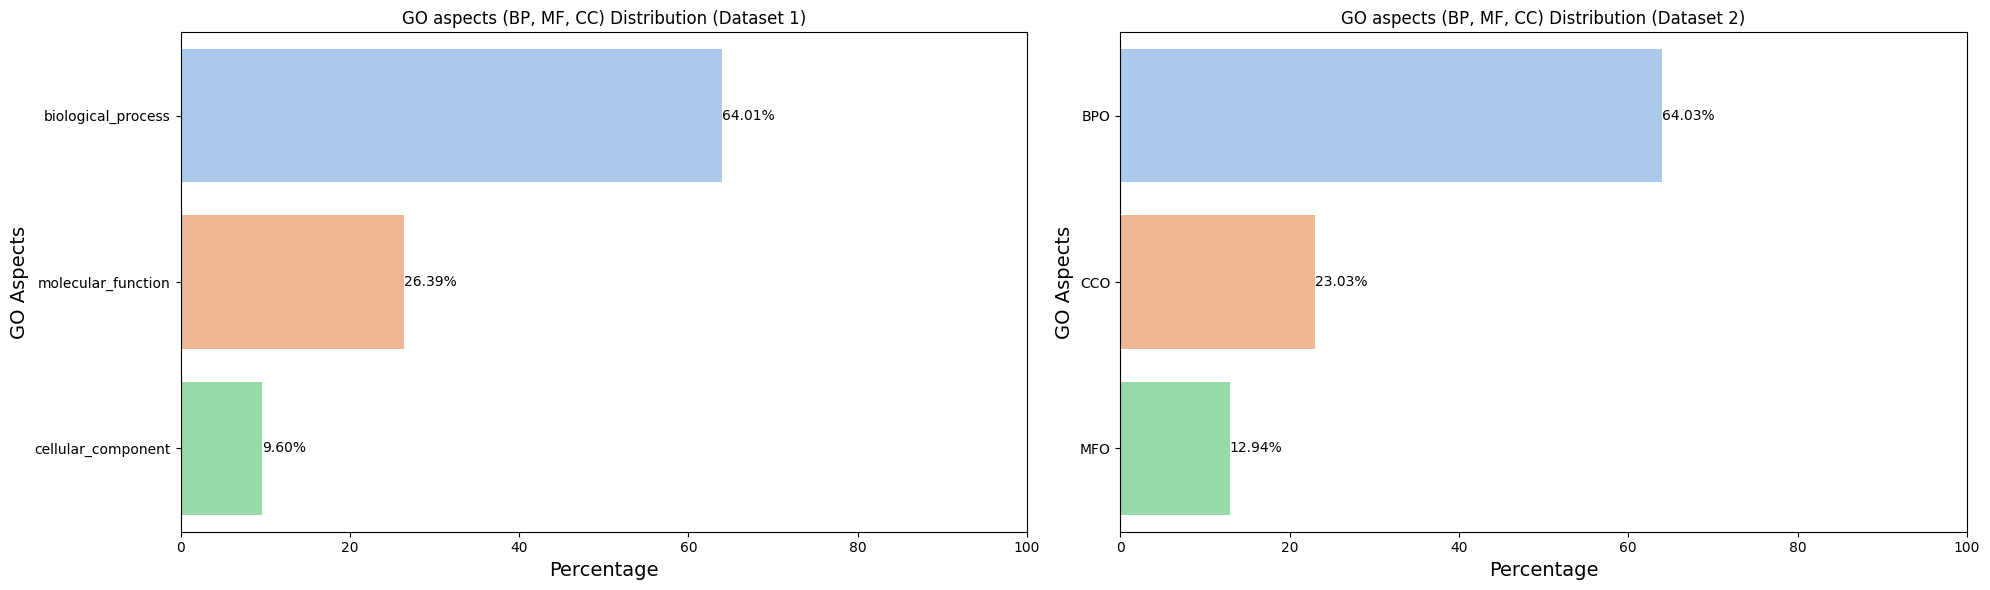

In [21]:
plot_ratio_compare(go_df, associations_df)

### Load (filtered) Sequences and Parse

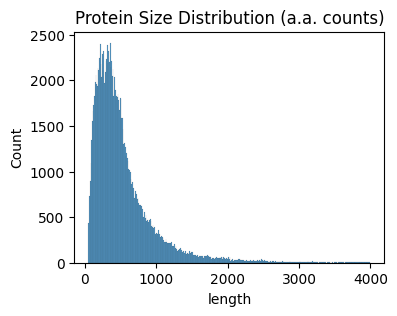

Sequences df dims: (140233, 3)
     uniprot_id                                           sequence  length
587  A0A0G2K6R9  MMNEDAAQKSDSGEKFNGSSQRRKRPKKSDSNASFLRAARAGNLDK...    3998
588  A0A2R8Q1V0  MGRFTIYRVLKKSGLSGLKVLKPQKCSFQPCSNTLTYTCQDCICYN...    3997
589      Q9Y4D8  MPANHLPIGSTMSTVHLSSDGTYFYWIWSPASLNEKTPKGHSVFMD...    3996
590  A0A5F9ZH30  MTTMLQKSDSNASFLRAARAGNLDKVVEYLKGGIDINTCNQNGLNA...    3995
591      Q80TY5  MLESYVTPILMSYVNRYIKNLKPSDLQLSLWGGDVVLSKLELKLDV...    3993


In [22]:
# Load and parse sequences from CAFA5

min_length = 50  # Minimum length threshold
max_length = 4000  # Maximum length threshold

# Load sequences and build df
file_path = data_folder / "cafa/train_sequences.fasta"
sequences = []
for record in SeqIO.parse(file_path, "fasta"):
    sequences.append(
        {
            "uniprot_id": record.id,
            "sequence": str(record.seq),
            "length": len(record.seq),
        }
    )

# Convert list of dictionaries to DataFrame
sequences_df = pd.DataFrame(sequences)
sequences_df = sequences_df.sort_values(by="length", ascending=False).reset_index(
    drop=True
)

# Filter sequences based on length
sequences_df_filtered = sequences_df[
    (sequences_df["length"] <= max_length) & (sequences_df["length"] >= min_length)
]

# Filter out proteins with obsolete GO terms (assuming go_nodes is defined)
valid_uniprot_ids = associations_df["uniprot_id"].to_numpy()  # extract ids of selected lenght range

filtered_sequences_df = sequences_df_filtered[
    sequences_df_filtered["uniprot_id"].isin(valid_uniprot_ids)
].reset_index(drop=True)

# Plot histogram of protein sizes
plt.figure(figsize=(4, 3))
sns.histplot(sequences_df_filtered, x="length", binwidth=10).set(
    title="Protein Size Distribution (a.a. counts)"
)
plt.savefig(data_folder / "cafa/cafa_protein_size_dist.png", dpi=300)
plt.show()

# Save the filtered data
sequences_df_filtered.to_csv(data_folder / "cafa/sequences.csv", index=False)

print(f"Sequences df dims: {sequences_df_filtered.shape}")
print(sequences_df_filtered.head())

### Load PPI Data (DIP)

In [23]:
# Load PPI data (DIP human) and preprocess

file_path = data_folder / "dip/Hsapi20170205.txt"  # human PPI
# file_path = data_folder / "dip/Dmela20170205.txt"  # droso PPI
# file_path = data_folder / "dip/Scere20170205.txt"  # yeast PPI
# file_path = data_folder /"dip/Mmusc20170205.txt"  # mice PPI
# file_path = data_folder / "dip/Ecoli20170205.txt"  # ecoli PPI

ppi_df = pd.read_csv(file_path, delimiter=",", on_bad_lines="warn")

print(ppi_df.info())
ppi_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7794 entries, 0 to 7793
Data columns (total 16 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   ID interactor A                  7794 non-null   object
 1   ID interactor B                  7794 non-null   object
 2   Alt. ID interactor A             7794 non-null   object
 3   Alt. ID interactor B             7794 non-null   object
 4   Alias(es) interactor A           7794 non-null   object
 5   Alias(es) interactor B           7794 non-null   object
 6   Interaction detection method(s)  7794 non-null   object
 7   Publication 1st author(s)        7794 non-null   object
 8   Publication Identifier(s)        7794 non-null   object
 9   Taxid interactor A               7794 non-null   object
 10  Taxid interactor B               7794 non-null   object
 11  Interaction type(s)              7794 non-null   object
 12  Source database(s)               7

,ID interactor A,ID interactor B,Alt. ID interactor A,Alt. ID interactor B,Alias(es) interactor A,Alias(es) interactor B,Interaction detection method(s),Publication 1st author(s),Publication Identifier(s),Taxid interactor A,Taxid interactor B,Interaction type(s),Source database(s),Interaction identifier(s),Confidence value(s),Processing Status
0,DIP-617N|refseq:NP_000607|uniprotkb:P01730,DIP-617N|refseq:NP_000607|uniprotkb:P01730,-,-,-,-,MI:0114(x-ray crystallography)|MI:0031(protein...,-,pubmed:9168119|pubmed:DIP-17838S|pubmed:916811...,taxid:9606(Homo sapiens),taxid:9606(Homo sapiens),MI:0407(direct interaction)|MI:0407(direct int...,MI:0465(dip),DIP-42E,dip-quality-status:core,dip:0004(small scale)|dip:0004(small scale)
1,DIP-493N|uniprotkb:Q62311,DIP-147N|uniprotkb:P21675,-,-,-,-,MI:0019(coimmunoprecipitation)|MI:0404(comigra...,-,pubmed:7667268|pubmed:DIP-231S|pubmed:7667268|...,taxid:10090(Mus musculus),taxid:9606(Homo sapiens),MI:0218(physical interaction)|MI:0218(physical...,MI:0465(dip),DIP-172E,dip-quality-status:core,dip:0002(small scale)|dip:0002(small scale)|di...
2,DIP-472N|refseq:NP_005047|uniprotkb:P29375,DIP-582N|refseq:NP_000312|uniprotkb:P06400,-,-,-,-,MI:0401(biochemical)|MI:0006(anti bait coimmun...,-,pubmed:8414517|pubmed:DIP-109S|pubmed:22615382...,taxid:9606(Homo sapiens),taxid:9606(Homo sapiens),MI:0218(physical interaction)|MI:0915(physical...,MI:0465(dip),DIP-214E,dip-quality-status:core,dip:0002(small scale)|dip:0004(small scale)|di...
3,DIP-1078N|refseq:NP_003185|uniprotkb:P20226,DIP-51N|uniprotkb:P09086,-,-,-,-,MI:0019(coimmunoprecipitation)|MI:0401(biochem...,-,pubmed:8202368|pubmed:DIP-468S|pubmed:8202368|...,taxid:9606(Homo sapiens),taxid:9606(Homo sapiens),MI:0218(physical interaction)|MI:0218(physical...,MI:0465(dip),DIP-320E,dip-quality-status:core,dip:0002(small scale)|dip:0002(small scale)
4,DIP-189N|refseq:NP_005179|uniprotkb:P22681,DIP-199N|refseq:refseq|uniprotkb:P46108,-,-,-,-,MI:0045(experimental interaction detection),-,pubmed:9178909|pubmed:DIP-185S,taxid:9606(Homo sapiens),taxid:9606(Homo sapiens),MI:0218(physical interaction),MI:0465(dip),DIP-401E,dip-quality-status:core,dip:0002(small scale)


In [24]:
# Preprocess dataset

# Keep only relevant columns
ppi_df.drop(
    columns=[
        "Alt. ID interactor A",
        "Alt. ID interactor B",
        "Alias(es) interactor A",
        "Alias(es) interactor B",
        "Publication 1st author(s)",
        "Publication Identifier(s)",
        "Source database(s)",
        "Interaction identifier(s)",
        "Processing Status",
    ],
    inplace=True,
)


# Rename remaining columns
new_column_names = {
    "ID interactor A": "uniprot_id_A",
    "ID interactor B": "uniprot_id_B",
    "Interaction detection method(s)": "detection_method",
    "Taxid interactor A": "taxiID_A",
    "Taxid interactor B": "taxiID_B",
    "Interaction type(s)": "ppi_type",
    "Confidence value(s)": "confidence",
}

ppi_df.rename(columns=new_column_names, inplace=True)

# Reorder columns
ppi_df = ppi_df[
    [
        "uniprot_id_A",
        "uniprot_id_B",
        "ppi_type",
        "detection_method",
        "confidence",
        "taxiID_A",
        "taxiID_B",
    ]
]

# Format data

# Extract uniprot ids
ppi_df["uniprot_id_A"] = ppi_df["uniprot_id_A"].apply(extract_uniprot_ids)
ppi_df["uniprot_id_B"] = ppi_df["uniprot_id_B"].apply(extract_uniprot_ids)

# Extract methods
ppi_df["detection_method"] = ppi_df["detection_method"].apply(extract_methods)

# Extract taxIDs
ppi_df["taxiID_A"] = ppi_df["taxiID_A"].apply(extract_taxiIDs)
ppi_df["taxiID_B"] = ppi_df["taxiID_B"].apply(extract_taxiIDs)

# Extract PPI type
ppi_df["ppi_type"] = ppi_df["ppi_type"].apply(extract_ppi_type)

# Extract confidence score
ppi_df["confidence"] = ppi_df["confidence"].apply(extract_confidence_score)

# Remove PPI pairs of diferent organisms
ppi_df = ppi_df[ppi_df["taxiID_A"] == ppi_df["taxiID_B"]]
ppi_df.reset_index(drop=True, inplace=True)

# Filter out PPI pairs without associations (protein-GO)
unique_associations_protein_ids = associations_df["uniprot_id"].unique()
ppi_df = ppi_df[
    (ppi_df["uniprot_id_A"].isin(unique_associations_protein_ids))
    & (ppi_df["uniprot_id_B"].isin(unique_associations_protein_ids))
]

# Remove self-loops (A = B)
ppi_df = ppi_df[(ppi_df["uniprot_id_A"] != ppi_df["uniprot_id_B"])]

# Remove proteins without embeddings (large proteins)
unique_sequences_protein_ids = sequences_df["uniprot_id"].unique()
ppi_df = ppi_df[
    (ppi_df["uniprot_id_A"].isin(unique_sequences_protein_ids))
    & (ppi_df["uniprot_id_B"].isin(unique_sequences_protein_ids))
]

# Handling NA values in uniprot IDs
# There are entries without reference to Uniprot IDs
print(
    "# of missing UniProt IDs (A, B):",
    (
        len(ppi_df[ppi_df["uniprot_id_A"].isna()]),
        len(ppi_df[ppi_df["uniprot_id_B"].isna()]),
    ),
)

# Drop NAs
ppi_df.dropna(inplace=True)

# Reset index and save processed df
ppi_df.reset_index(drop=True, inplace=True)
ppi_df.to_csv(species_folder / "datasets/ppi.csv", index=False)

print(f"PPI df shape: {ppi_df.shape}")
print(ppi_df.head().to_markdown())
ppi_df.describe()

# of missing UniProt IDs (A, B): (0, 0)
PPI df shape: (4683, 7)
|    | uniprot_id_A   | uniprot_id_B   | ppi_type                                  | detection_method                                                            | confidence   |   taxiID_A |   taxiID_B |
|---:|:---------------|:---------------|:------------------------------------------|:----------------------------------------------------------------------------|:-------------|-----------:|-----------:|
|  0 | P29375         | P06400         | physical association;physical interaction | biochemical;anti bait coimmunoprecipitation;anti bait coimmunoprecipitation | core         |       9606 |       9606 |
|  1 | P20226         | P09086         | physical interaction                      | coimmunoprecipitation;biochemical                                           | core         |       9606 |       9606 |
|  2 | P22681         | P46108         | physical interaction                      | experimental interaction detection 

,uniprot_id_A,uniprot_id_B,ppi_type,detection_method,confidence,taxiID_A,taxiID_B
count,4683,4683,4683,4683,4683,4683,4683
unique,2144,2105,53,1075,2,1,1
top,P04637,P04637,physical association,anti tag coimmunoprecipitation,core,9606,9606
freq,29,37,2705,622,4536,4683,4683


### Extract Metadata

In [25]:
# Obtain PPI metadata

# Check PPI types in the dataset
# Get unique lists of ppi types
ppi_types = ppi_df["ppi_type"].unique()

# Get unique PPI types from lists of PPI types
unique_ppi_types = set(
    ppi_type.strip() for sublist in ppi_types for ppi_type in sublist.split(";")
)
unique_ppi_types = sorted(unique_ppi_types)  # convert to list

# Save list
file_path = species_folder / "metadata/ppi_types.txt"
with open(file_path, "w") as f:
    f.write(str(unique_ppi_types))

# Check PPI detection methods in the dataset
# Get unique lists of detection methods
methods = ppi_df["detection_method"].unique()

# Get unique PPI types from lists of PPI types
unique_methods = set(
    method.strip() for sublist in methods for method in sublist.split(";")
)
unique_methods = sorted(unique_methods)  # convert to list

# Save list
file_path = species_folder / "metadata/ppi_methods.txt"
with open(file_path, "w") as f:
    f.write(str(unique_methods))

print(f"# of unique PPI detection methods: {len(unique_methods)}")
print(unique_methods[:5])
print(f"# of unique PPI types: {len(unique_ppi_types)}")
print(unique_ppi_types)

# of unique PPI detection methods: 85
['Split renilla luciferase complementation', 'acetylation assay', 'adp ribosylase assay', 'affinity chromatography technology', 'amplified luminescent proximity homogeneous assay']
# of unique PPI types: 20
['acetylation reaction', 'adp ribosylation reaction', 'ampylation reaction', 'association', 'cleavage reaction', 'covalent binding', 'deacetylation reaction', 'demethylation reaction', 'dephosphorylation reaction', 'deubiquitination reaction', 'direct interaction', 'disulfide bond', 'genetic interference', 'hydroxylation reaction', 'methylation reaction', 'oxidoreductase activity electron transfer assay', 'phosphorylation reaction', 'physical association', 'physical interaction', 'protein cleavage']


In [26]:
# PPI counts (unique)

# Extract interactions
ppi_pairs = list(
    tuple(sorted(x)) for x in ppi_df[["uniprot_id_A", "uniprot_id_B"]].to_numpy()
)

# Extract unique interactions
ppi_unique_pairs = list(
    set(tuple(sorted(x)) for x in ppi_df[["uniprot_id_A", "uniprot_id_B"]].to_numpy())
)

# Extract unique uniprot ids in interactions
ppi_unique_ids = pd.concat([ppi_df["uniprot_id_A"], ppi_df["uniprot_id_B"]]).unique()

print(f"# of unique UniProt IDs: {ppi_unique_ids.shape[0]}")
print(f"# of PPIs: {len(ppi_pairs)}")
print(f"# of unique PPIs: {len(ppi_unique_pairs)}")

# of unique UniProt IDs: 2955
# of PPIs: 4683
# of unique PPIs: 4666


### Build NetworkX Graph to Extract LCC

In [27]:
# Construct nx graph to extract LCC

# Create undirected graph instance
ppi_graph = nx.Graph()

# Add edges
ppi_graph.add_edges_from(ppi_unique_pairs)

# Get connected components and lcc
cc = list(nx.connected_components(ppi_graph))
lcc = max(cc, key=len)

# Extract subgraph with lcc
ppi_graph_lcc = ppi_graph.subgraph(lcc).copy()

# Extract nodes and edges for graph dataset
ppi_nodes = ppi_graph_lcc.nodes()
ppi_edges = list(ppi_graph_lcc.edges())

# print-out basic graph attributes
print(f"# of nodes: {ppi_graph.number_of_nodes()}")
print(f"# of edges: {ppi_graph.number_of_edges()}")
print(f"Is connected?: {nx.is_connected(ppi_graph_lcc)}")
print(f"\n# of connected components: {len(cc)}")
print(f"\n# of nodes (LCC): {len(ppi_nodes)}")
print(f"# of edges (LCC): {len(ppi_edges)}")
print(f"Is connected? (LCC): {nx.is_connected(ppi_graph_lcc)}")

# of nodes: 2955
# of edges: 4666
Is connected?: True

# of connected components: 198

# of nodes (LCC): 2366
# of edges (LCC): 4209
Is connected? (LCC): True


In [28]:
# PPI counts

# Extract unique interactions
ppi_unique_pairs = list(
    set(tuple(sorted(x)) for x in ppi_df[["uniprot_id_A", "uniprot_id_B"]].to_numpy())
)
# Extract unique uniprot ids in interactions
ppi_unique_ids = pd.concat([ppi_df["uniprot_id_A"], ppi_df["uniprot_id_B"]]).unique()

print(f"# of unique UniProt IDs: {ppi_unique_ids.shape[0]}")
print(f"# of unique PPIs: {len(ppi_unique_pairs)}")

# of unique UniProt IDs: 2955
# of unique PPIs: 4666


In [29]:
# Filter protein-go associations with LCC nodes

# Keep full protein-GO associations for plotting
associations_full = associations_df.copy()

# Remove associations with large proteins
associations_df = associations_df[
    associations_df["uniprot_id"].isin(list(ppi_graph_lcc.nodes()))
].copy()

associations_df = associations_df[
    associations_df["uniprot_id"].isin(sequences_df_filtered["uniprot_id"].unique())
]
associations_df.reset_index(drop=True, inplace=True)

# Save filtered df
file_path = species_folder / "datasets/associations.tsv"
associations_df.to_csv(file_path, sep="\t", index=False)


print(f"Filtered Protein-GO associations dims: {associations_df.shape}")
print(f"# of unique UniProt IDs: {len(associations_df['uniprot_id'].unique())}")
associations_df.head()

Filtered Protein-GO associations dims: (242511, 3)
# of unique UniProt IDs: 2352


,uniprot_id,go_id,aspect
0,A1YPR0,GO:0050789,BPO
1,A1YPR0,GO:0048523,BPO
2,A1YPR0,GO:0048519,BPO
3,A1YPR0,GO:0065007,BPO
4,A1YPR0,GO:0008285,BPO


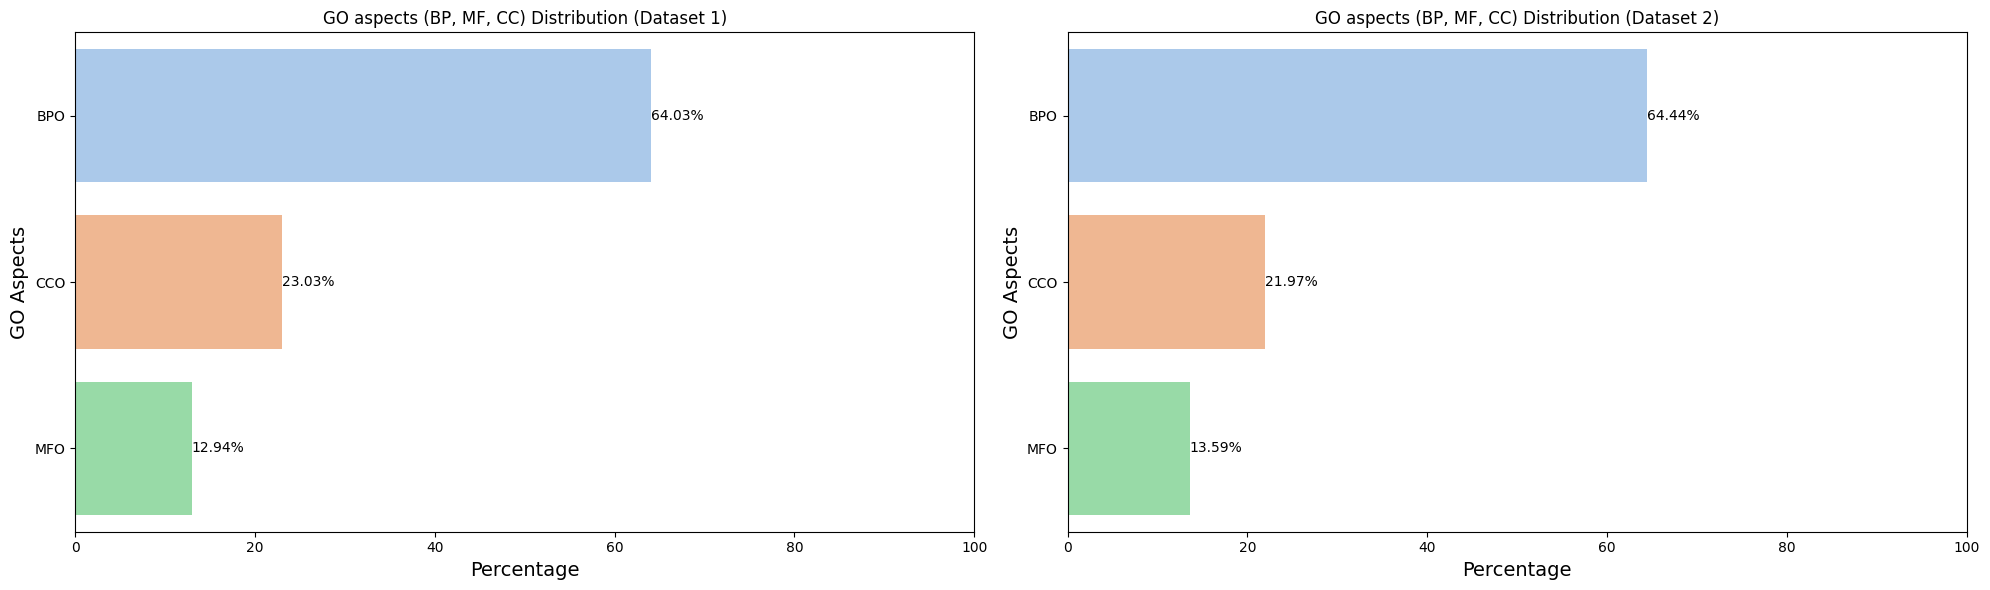

In [30]:
plot_ratio_compare(associations_full, associations_df)

### Build PPI Graph

In [31]:
# Load embeddings

emb_dataset = ProteinEmbeddingDataset(data_folder / "cafa/protein_embeddings")

print(f"# of protein embeddings: {len(emb_dataset)}")

# of protein embeddings: 140233


In [ ]:
# Collect uniprot ids and embeddings from Dataloader

# iterates over dataset in batches to extract sequences and ids
protein_embed_dict = {}
unique_proteins_lcc_cafa = associations_df["uniprot_id"].unique()

loader = DataLoader(emb_dataset, batch_size=1, shuffle=False)
for batch in tqdm(loader, total=len(loader), desc="Loading Protein Dataset..."):
    uniprot_id = str(batch["uniprot_id"][0])
    if batch["uniprot_id"][0] in unique_proteins_lcc_cafa:
        protein_embed_dict[batch["uniprot_id"][0]] = batch["tensor"].numpy().flatten()

# Save protein embeddings dict
save_file_path = species_folder / "datasets/protein_embeddings.pkl"
with open(save_file_path, "wb") as file:
    pickle.dump(protein_embed_dict, file)

# Convert embeddings to tensors
protein_feats = torch.stack(
    [torch.tensor(v, dtype=torch.float32) for v in protein_embed_dict.values()]
)

# Create mapping dict
protein_ids = list(protein_embed_dict.keys())
protein_ids_map = dict(zip(protein_ids, range(len(ppi_nodes))))
protein_feats_map = dict(zip(protein_ids, protein_feats))

print(f"# of protein ids: {len(protein_ids)}")
print(f"protein feats shape: {protein_feats.shape}")

for key, value in protein_ids_map.items():
    print(f"key: {key}, value: {value}")
    break

for key, value in protein_feats_map.items():
    print(f"key: {key}, value: {value.shape}")
    break

In [32]:
# Load protein embeddings dict

# Get unique protein ids
unique_proteins_lcc_cafa = associations_df["uniprot_id"].unique()

# Load embeddings dict
save_file_path = species_folder / "datasets/protein_embeddings.pkl"
with open(save_file_path, "rb") as file:
    protein_embed_dict = pickle.load(file)

# Convert embeddings to tensors
protein_feats = torch.stack(
    [torch.tensor(v, dtype=torch.float32) for v in protein_embed_dict.values()]
)

# Create mapping dict
protein_ids = list(protein_embed_dict.keys())
protein_ids_map = dict(zip(protein_ids, range(len(ppi_nodes))))
protein_feats_map = dict(zip(protein_ids, protein_feats))

print(f"# of protein ids: {len(protein_ids)}")
print(f"protein feats shape: {protein_feats.shape}")

for key, value in protein_ids_map.items():
    print(f"key: {key}, value: {value}")
    break

for key, value in protein_feats_map.items():
    print(f"key: {key}, value: {value.shape}")
    break

# of protein ids: 2352
protein feats shape: torch.Size([2352, 1024])
key: Q71DI3, value: 0
key: Q71DI3, value: torch.Size([1024])


In [33]:
# Creates edge_index

# Extracts PPI pairs for edge construction

# Ensures that every pair of nodes intersect PPI / CAFA5
edges_to_tensor = [
    [protein_ids_map[e[0]], protein_ids_map[e[1]]]
    for e in ppi_edges
    if e[0] in unique_proteins_lcc_cafa and e[1] in unique_proteins_lcc_cafa
]

edge_index_ppi = torch.tensor(edges_to_tensor, dtype=torch.long).t().contiguous()

print(f"edge_index shape: {edge_index_ppi.shape}")
edge_index_ppi

edge_index shape: torch.Size([2, 4175])


tensor([[ 469,  469,  469,  ..., 1366, 1396, 1198],
        [1053, 2042, 1767,  ..., 1259,  686,  157]])

In [34]:
# Creates torch geometric Data object and save

ppi_data = Data()
ppi_data.x = protein_feats
ppi_data.edge_index = edge_index_ppi

save_file_path = species_folder / "datasets/ppi_dataset.pt"
torch.save(ppi_data, save_file_path)
ppi_data

Data(x=[2352, 1024], edge_index=[2, 4175])

## Prepare PPI-GO Heterodata

#### Mapping Protein and GO ids to Unique Integer Indices

In [35]:
# Map GO terms and Uniprot IDs to respective indexes

# Map go ids
associations_df["go_idx"] = associations_df["go_id"].map(go_ids_map)

# Map proteins ids
associations_df["uniprot_idx"] = associations_df["uniprot_id"].map(protein_ids_map)

# Save
associations_df.to_csv(species_folder / "datasets/associations_indices.csv", index=False)

associations_df

,uniprot_id,go_id,aspect,go_idx,uniprot_idx
0,A1YPR0,GO:0050789,BPO,23696,399
1,A1YPR0,GO:0048523,BPO,22606,399
2,A1YPR0,GO:0048519,BPO,22602,399
3,A1YPR0,GO:0065007,BPO,27192,399
4,A1YPR0,GO:0008285,BPO,5304,399
...,...,...,...,...,...
242506,Q9Y6X2,GO:0016740,MFO,8988,171
242507,Q9Y6X2,GO:0003674,MFO,2367,171
242508,Q9Y6X2,GO:0140096,MFO,33948,171
242509,Q9Y6X2,GO:0005515,MFO,3534,171


#### Creating Protein-GO Positive Edges Index

In [36]:
# Create inter graph edges (UniProt -> GO)

edge_index_protgo_positive = torch.tensor(
    [
        associations_df["uniprot_idx"].values,
        associations_df["go_idx"].values,
    ],
    dtype=torch.long,
)

print(
    f"Protein associates with GO edge index shape: {edge_index_protgo_positive.shape}"
)
edge_index_protgo_positive

Protein associates with GO edge index shape: torch.Size([2, 242511])


tensor([[  399,   399,   399,  ...,   171,   171,   171],
        [23696, 22606, 22602,  ..., 33948,  3534, 10713]])

Negative edges generation is feasible.
Generating 242511 negative edges...
Protein negative associates with GO edge index shape: torch.Size([2, 242511])


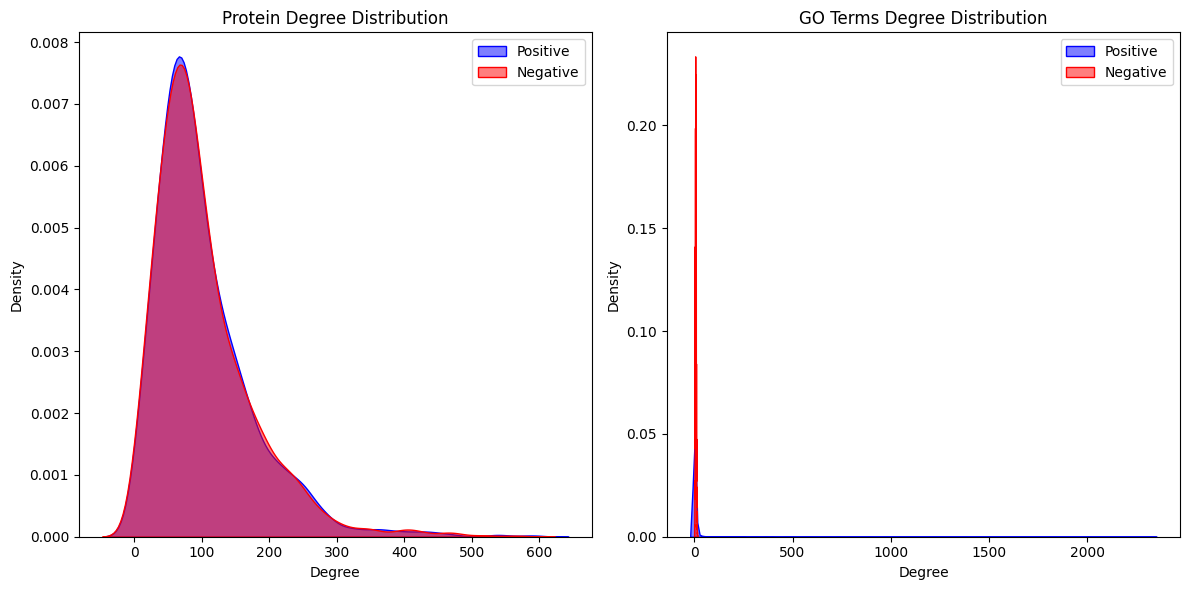

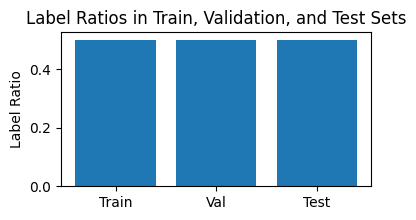

Labels (ratio): train (0.50), val (0.50), test (0.50)
HeteroData(
  protein={
    x=[2352, 1024],
    id=[2352],
  },
  go={
    x=[42255, 384],
    id=[42255],
  },
  (protein, ppi, protein)={ edge_index=[2, 4175] },
  (go, relation, go)={ edge_index=[2, 81848] },
  (protein, associates_with, go)={
    edge_index=[2, 485022],
    edge_label=[485022],
    train_mask=[485022],
    val_mask=[485022],
    test_mask=[485022],
  }
)


In [37]:
# Create negative edges

# Instantiate ProteinGO dataset class
protgo_dataset = ProteinGoDataset(
    protein_ids_map=protein_ids_map,
    go_ids_map=go_ids_map,
    species_folder=species_folder,
)

# generate hetero dataset
protgo_dataset.process(
    edge_index_protgo_positive=edge_index_protgo_positive,
    protein_feats=protein_feats,
    go_feats=go_feats,
    protein_ids=protein_ids,
    go_ids=go_ids,
    edge_index_ppi=edge_index_ppi,
    edge_index_go=edge_index_go,
    train_ratio=0.8,
    ratio=1,
)

## Training

In [38]:
# Define output dim

output_dim = 512
dropout_rate = 0.4
n_heads = 8
n_epochs = 250
patience = 50
learning_rate = 0.01
weight_decay = 1e-5

### GAT Model GPU (baseline)

In [ ]:
class HGNNGAT(torch.nn.Module):
    def __init__(
        self,
        protein_features,
        go_features,
        out_features,
        dropout=0.6,
        heads=8,
        concat=True,
    ):
        super(HGNNGAT, self).__init__()
        # Calculate the number of output features per head
        per_head_features = out_features // heads if concat else out_features

        # Initialize GAT layers for each type of connection with multi-head attention
        self.conv1_protein = GATConv(
            protein_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
        )
        self.conv1_go = GATConv(
            go_features, per_head_features, heads=heads, concat=concat, dropout=dropout
        )
        self.conv2_protein = GATConv(
            out_features, per_head_features, heads=heads, concat=concat, dropout=dropout
        )
        self.conv2_go = GATConv(
            out_features, per_head_features, heads=heads, concat=concat, dropout=dropout
        )

        # Adjust the output feature size based on concatenation or averaging of heads
        final_out_features = out_features if concat else per_head_features

        # Linear layers for making predictions
        self.protein_to_go = Linear(final_out_features * 2, 1)

    def forward(self, x_dict, edge_index_dict, mask=None):
        # Apply the first convolution layer to protein and GO nodes
        x_protein = F.elu(
            self.conv1_protein(
                x_dict["protein"], edge_index_dict[("protein", "ppi", "protein")]
            )
        )
        x_go = F.elu(
            self.conv1_go(x_dict["go"], edge_index_dict[("go", "relation", "go")])
        )

        # Apply the second convolution layer
        x_protein = F.elu(
            self.conv2_protein(
                x_protein, edge_index_dict[("protein", "ppi", "protein")]
            )
        )
        x_go = F.elu(self.conv2_go(x_go, edge_index_dict[("go", "relation", "go")]))

        # Handling edges based on the mask
        edge_index_protein_go = edge_index_dict[("protein", "associates_with", "go")]
        if mask is not None:
            edge_index_protein_go = edge_index_protein_go[:, mask]
        protein_features = x_protein[
            edge_index_protein_go[0]
        ]  # Source protein features
        go_features = x_go[edge_index_protein_go[1]]  # Target GO features

        # Concatenate features from proteins and GOs
        association_features = torch.cat([protein_features, go_features], dim=1)

        # Predict association
        association_scores = self.protein_to_go(association_features).squeeze()
        return association_scores

In [ ]:
def train(
    model,
    dataset,
    epochs,
    batch_size=32,
    save_path=None,
    patience=10,
    learning_rate=0.001,
    weight_decay=1e-5,
    device="cuda" if torch.cuda.is_available() else "cpu",
):

    # Send model and data to gpu
    model.to(device)
    dataset.to_device(device)
    dataset.create_data_loaders(batch_size=batch_size)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=learning_rate, weight_decay=weight_decay
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        "min",
        patience=10,
        factor=0.1,
        verbose=True,
    )

    best_val_loss = float("inf")  # Initialize the best validation loss to a large value
    best_val_auroc = 0  # Initialize the best validation AUROC
    early_stopping_counter = 0  # Counter for early stopping

    # Initialize dictionaries to keep training metrics
    metrics = {
        "train_losses": {},
        "train_aurocs": {},
        "val_losses": {},
        "val_aurocs": {},
    }

    save_path = Path(save_path)
    save_path.mkdir(parents=True, exist_ok=True)

    for epoch in tqdm(range(1, epochs + 1), desc="Training Prot2GO HGNN..."):
        model.train()
        train_loss = 0
        train_predictions = []
        train_labels = []

        for edge_index, edge_label in dataset.train_loader:
            optimizer.zero_grad()
            edge_index = edge_index.to(device)
            edge_label = edge_label.to(device)

            out = model(
                {
                    "protein": dataset.hetero_data["protein"].x.to(device),
                    "go": dataset.hetero_data["go"].x.to(device),
                },
                {
                    ("protein", "ppi", "protein"): dataset.hetero_data[
                        "protein", "ppi", "protein"
                    ].edge_index.to(device),
                    ("go", "relation", "go"): dataset.hetero_data[
                        "go", "relation", "go"
                    ].edge_index.to(device),
                    ("protein", "associates_with", "go"): edge_index.t(),
                },
            )
            loss = F.binary_cross_entropy_with_logits(out, edge_label)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            train_predictions.append(out.sigmoid().detach().cpu().numpy())
            train_labels.append(edge_label.cpu().numpy())

        train_loss /= len(dataset.train_loader)
        train_predictions = np.concatenate(train_predictions)
        train_labels = np.concatenate(train_labels)
        train_auroc = roc_auc_score(train_labels, train_predictions)

        metrics["train_losses"][epoch] = train_loss
        metrics["train_aurocs"][epoch] = train_auroc

        model.eval()
        with torch.no_grad():
            val_loss = 0
            val_predictions = []
            val_labels = []

            for edge_index, edge_label in dataset.val_loader:
                edge_index = edge_index.to(device)
                edge_label = edge_label.to(device)

                out = model(
                    {
                        "protein": dataset.hetero_data["protein"].x.to(device),
                        "go": dataset.hetero_data["go"].x.to(device),
                    },
                    {
                        ("protein", "ppi", "protein"): dataset.hetero_data[
                            "protein", "ppi", "protein"
                        ].edge_index.to(device),
                        ("go", "relation", "go"): dataset.hetero_data[
                            "go", "relation", "go"
                        ].edge_index.to(device),
                        ("protein", "associates_with", "go"): edge_index.t(),
                    },
                )
                loss = F.binary_cross_entropy_with_logits(out, edge_label)
                val_loss += loss.item()
                val_predictions.append(out.sigmoid().cpu().numpy())
                val_labels.append(edge_label.cpu().numpy())

            val_loss /= len(dataset.val_loader)
            val_predictions = np.concatenate(val_predictions)
            val_labels = np.concatenate(val_labels)
            val_auroc = roc_auc_score(val_labels, val_predictions)

            metrics["val_losses"][epoch] = val_loss
            metrics["val_aurocs"][epoch] = val_auroc

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_val_auroc = val_auroc
                best_weights_path = save_path / "best_model_weights.pt"
                torch.save(model.state_dict(), best_weights_path)
                early_stopping_counter = 0
            else:
                early_stopping_counter += 1

            if early_stopping_counter >= patience:
                print(f"Early stopping triggered after {epoch} epochs.")
                break

        scheduler.step(val_loss)

        if epoch % 10 == 0:
            print(f"Epoch {epoch}:")
            print(
                f"  Avg Training Loss: {train_loss:.3f}, Avg Training AUROC: {train_auroc:.3f}"
            )
            print(
                f"  Avg Validation Loss: {val_loss:.3f}, Avg Validation AUROC: {val_auroc:.3f}"
            )

    torch.save(model.state_dict(), save_path / "final_model_weights.pt")

    return metrics

In [ ]:
# Instantiate model
model = HGNNGAT(
    protein_features=1024,
    go_features=384,
    out_features=128,
    dropout=dropout_rate,
    heads=n_heads,
)

# Define sub-folder for model architecture
save_path = species_folder / "models/baseline_gpu"

# Train
metrics_dict = train(
    model=model,
    dataset=protgo_dataset,
    epochs=n_epochs,
    batch_size=20000,
    save_path=save_path,
    patience=patience,
    learning_rate=learning_rate,
    weight_decay=weight_decay,
)

# Plot training metrics
plot_loss_and_accuracy(metrics_dict, save_path)

In [ ]:

# Evaluate test set
model.load_state_dict(torch.load(save_path / "best_model_weights.pt"))
test_results = evaluate_model_performance(
    model,
    protgo_dataset,
    associations_df,
    go_ids_map,
    save_path,
)

test_results

### GAT Model GPU - Normalized Attention (SoftMax) and Focused Attention

In [42]:
class FocusedGATConv(GATConv):
    def __init__(self, *args, sample_size=8, high_degree_threshold=10, **kwargs):
        super(FocusedGATConv, self).__init__(*args, **kwargs)
        self.sample_size = sample_size
        self.high_degree_threshold = high_degree_threshold

    def forward(self, x, edge_index, return_attention_weights=False):
        row, col = edge_index
        deg = degree(row, x.size(0), dtype=x.dtype)

        # Efficient tensor operations for neighbor sampling
        sampled_edges = []
        for node in range(x.size(0)):
            neighbors = col[row == node]
            if len(neighbors) > self.sample_size:
                if deg[node] > self.high_degree_threshold:
                    sampled_neighbors = neighbors[
                        torch.randint(len(neighbors), (int(self.sample_size * 0.5),))
                    ]
                else:
                    sampled_neighbors = neighbors[
                        torch.randint(len(neighbors), (self.sample_size,))
                    ]
            else:
                sampled_neighbors = neighbors
            sampled_edges.append(
                torch.stack(
                    [torch.full_like(sampled_neighbors, node), sampled_neighbors], dim=0
                )
            )

        sampled_edges = torch.cat(sampled_edges, dim=1)

        # Call the original forward method to compute attention
        out = super().forward(x, sampled_edges, return_attention_weights=True)
        x, (edge_index, alpha) = out

        # Apply softmax normalization to the attention coefficients
        alpha = F.softmax(alpha, dim=1)

        # If return_attention_weights is True, return x and alpha, else return only x
        if return_attention_weights:
            return x, (edge_index, alpha)
        else:
            return x

In [43]:
# Model Class
class HGNNGATNorm(torch.nn.Module):
    def __init__(
        self,
        protein_features,
        go_features,
        out_features,
        dropout=0.6,
        heads=8,
        concat=True,
        add_self_loops=True,
        sample_size=8,
        high_degree_threshold=10,
    ):
        super(HGNNGATNorm, self).__init__()
        per_head_features = out_features // heads if concat else out_features

        self.conv1_protein = FocusedGATConv(
            protein_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
            add_self_loops=add_self_loops,
            sample_size=sample_size,
            high_degree_threshold=high_degree_threshold,
        )
        self.conv1_go = FocusedGATConv(
            go_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
            add_self_loops=add_self_loops,
            sample_size=sample_size,
            high_degree_threshold=high_degree_threshold,
        )
        self.conv2_protein = FocusedGATConv(
            out_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
            add_self_loops=add_self_loops,
            sample_size=sample_size,
            high_degree_threshold=high_degree_threshold,
        )
        self.conv2_go = FocusedGATConv(
            out_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
            add_self_loops=add_self_loops,
            sample_size=sample_size,
            high_degree_threshold=high_degree_threshold,
        )

        final_out_features = out_features if concat else per_head_features
        self.fc1 = Linear(final_out_features * 2, final_out_features)
        self.bn1 = BatchNorm1d(final_out_features)
        self.fc2 = Linear(final_out_features, 1)
        self.dropout = dropout

        # Fully connected layer to learn the projection from concatenated features to output
        self.protein_to_go = Linear(final_out_features * 2, 1)

        # Initialize weights
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, Linear):
                torch.nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    torch.nn.init.zeros_(m.bias)

    def forward(self, x_dict, edge_index_dict, mask=None, fc_layers=True):
        x_protein = F.elu(
            self.conv1_protein(
                x_dict["protein"], edge_index_dict[("protein", "ppi", "protein")]
            )
        )
        x_go = F.elu(
            self.conv1_go(x_dict["go"], edge_index_dict[("go", "relation", "go")])
        )
        x_protein = F.elu(
            self.conv2_protein(
                x_protein, edge_index_dict[("protein", "ppi", "protein")]
            )
        )
        x_go = F.elu(self.conv2_go(x_go, edge_index_dict[("go", "relation", "go")]))

        edge_index_protein_go = edge_index_dict[("protein", "associates_with", "go")]
        if mask is not None:
            edge_index_protein_go = edge_index_protein_go[:, mask]

        protein_features = x_protein[edge_index_protein_go[0]]
        go_features = x_go[edge_index_protein_go[1]]
        association_features = torch.cat([protein_features, go_features], dim=1)

        if fc_layers:
            # Pass through additional fully connected layers with batch normalization and dropout
            x = F.leaky_relu(self.bn1(self.fc1(association_features)))
            x = F.dropout(x, p=self.dropout, training=self.training)
            association_scores = self.fc2(x).squeeze()
        else:
            association_scores = self.protein_to_go(association_features).squeeze()

        return association_scores

    def get_attention_weights(self, x_dict, edge_index_dict):
        self.eval()
        with torch.no_grad():
            x_protein, (edge_index_protein_1, attn_weights_protein_1) = (
                self.conv1_protein(
                    x_dict["protein"],
                    edge_index_dict[("protein", "ppi", "protein")],
                    return_attention_weights=True,
                )
            )
            x_go, (edge_index_go_1, attn_weights_go_1) = self.conv1_go(
                x_dict["go"],
                edge_index_dict[("go", "relation", "go")],
                return_attention_weights=True,
            )

            x_protein, (edge_index_protein_2, attn_weights_protein_2) = (
                self.conv2_protein(
                    x_protein,
                    edge_index_dict[("protein", "ppi", "protein")],
                    return_attention_weights=True,
                )
            )
            x_go, (edge_index_go_2, attn_weights_go_2) = self.conv2_go(
                x_go,
                edge_index_dict[("go", "relation", "go")],
                return_attention_weights=True,
            )

            return (
                (edge_index_protein_1, attn_weights_protein_1),
                (edge_index_go_1, attn_weights_go_1),
                (edge_index_protein_2, attn_weights_protein_2),
                (edge_index_go_2, attn_weights_go_2),
            )

In [47]:
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

def train(
    model,
    dataset,
    epochs,
    batch_size=32,
    accumulation_steps=None,
    save_path=None,
    patience=10,
    learning_rate=0.001,
    weight_decay=1e-5,
    device="cuda" if torch.cuda.is_available() else "cpu",
    num_workers=4,
):

    model.to(device)
    dataset.to_device(device)
    dataset.create_data_loaders(
        batch_size=batch_size, num_workers=num_workers, pin_memory=True
    )

    optimizer = torch.optim.Adam(
        model.parameters(), lr=learning_rate, weight_decay=weight_decay
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, "min", patience=10, factor=0.1, verbose=True
    )
    scaler = GradScaler()

    best_val_loss = float("inf")
    best_val_auroc = 0
    early_stopping_counter = 0

    metrics = {
        "train_losses": {},
        "train_aurocs": {},
        "val_losses": {},
        "val_aurocs": {},
    }

    save_path = Path(save_path)
    save_path.mkdir(parents=True, exist_ok=True)

    for epoch in tqdm(range(1, epochs + 1), desc="Epochs", unit="epoch"):
        model.train()
        train_loss = 0
        train_predictions = []
        train_labels = []

        for i, (edge_index, edge_label) in enumerate(
            tqdm(dataset.train_loader, desc="Batches", leave=False)
        ):
            edge_index = edge_index.to(device)
            edge_label = edge_label.to(device)

            with autocast():
                out = model(
                    {
                        "protein": dataset.hetero_data["protein"].x.to(device),
                        "go": dataset.hetero_data["go"].x.to(device),
                    },
                    {
                        ("protein", "ppi", "protein"): dataset.hetero_data[
                            "protein", "ppi", "protein"
                        ].edge_index.to(device),
                        ("go", "relation", "go"): dataset.hetero_data[
                            "go", "relation", "go"
                        ].edge_index.to(device),
                        ("protein", "associates_with", "go"): edge_index.t(),
                    },
                )
                loss = F.binary_cross_entropy_with_logits(out, edge_label)

            scaler.scale(loss).backward()

            if accumulation_steps is not None and (i + 1) % accumulation_steps == 0:
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad()

            train_loss += loss.item()
            train_predictions.append(out.sigmoid().detach().cpu().numpy())
            train_labels.append(edge_label.cpu().numpy())

        if accumulation_steps is None or (i + 1) % accumulation_steps != 0:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()

        train_loss /= len(dataset.train_loader)
        train_predictions = np.concatenate(train_predictions)
        train_labels = np.concatenate(train_labels)
        train_auroc = roc_auc_score(train_labels, train_predictions)

        metrics["train_losses"][epoch] = train_loss
        metrics["train_aurocs"][epoch] = train_auroc

        model.eval()
        with torch.no_grad():
            val_loss = 0
            val_predictions = []
            val_labels = []

            for edge_index, edge_label in tqdm(
                dataset.val_loader, desc="Validation Batches", leave=False
            ):
                edge_index = edge_index.to(device)
                edge_label = edge_label.to(device)

                with autocast():
                    out = model(
                        {
                            "protein": dataset.hetero_data["protein"].x.to(device),
                            "go": dataset.hetero_data["go"].x.to(device),
                        },
                        {
                            ("protein", "ppi", "protein"): dataset.hetero_data[
                                "protein", "ppi", "protein"
                            ].edge_index.to(device),
                            ("go", "relation", "go"): dataset.hetero_data[
                                "go", "relation", "go"
                            ].edge_index.to(device),
                            ("protein", "associates_with", "go"): edge_index.t(),
                        },
                    )
                    loss = F.binary_cross_entropy_with_logits(out, edge_label)

                val_loss += loss.item()
                val_predictions.append(out.sigmoid().cpu().numpy())
                val_labels.append(edge_label.cpu().numpy())

            val_loss /= len(dataset.val_loader)
            val_predictions = np.concatenate(val_predictions)
            val_labels = np.concatenate(val_labels)
            val_auroc = roc_auc_score(val_labels, val_predictions)

            metrics["val_losses"][epoch] = val_loss
            metrics["val_aurocs"][epoch] = val_auroc

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_val_auroc = val_auroc
                torch.save(model.state_dict(), save_path / "best_model_weights.pt")
                early_stopping_counter = 0
            else:
                early_stopping_counter += 1

            if early_stopping_counter >= patience:
                print(f"Early stopping triggered after {epoch} epochs.")
                break

        scheduler.step(val_loss)

        if epoch % 10 == 0:
            print(f"Epoch {epoch}:")
            print(
                f"  Avg Training Loss: {train_loss:.3f}, Avg Training AUROC: {train_auroc:.3f}"
            )
            print(
                f"  Avg Validation Loss: {val_loss:.3f}, Avg Validation AUROC: {val_auroc:.3f}"
            )

    torch.save(model.state_dict(), save_path / "final_model_weights.pt")

    return metrics

In [48]:
# Instantiate model
model = HGNNGATNorm(
    protein_features=1024,
    go_features=384,
    out_features=128,
    dropout=dropout_rate,
    heads=n_heads,
)

# Define sub-folder for model architecture
save_path = species_folder / "models/focusattn_softnorm_gpu"

# Train
metrics_dict = train(
    model=model,
    dataset=protgo_dataset,
    epochs=n_epochs,
    batch_size=16,
    accumulation_steps=4,
    save_path=save_path,
    patience=patience,
    learning_rate=learning_rate,
    weight_decay=weight_decay,
)

# Plot training metrics
plot_loss_and_accuracy(metrics_dict, save_path)

# Evaluate test set
model.load_state_dict(torch.load(save_path / "best_model_weights.pt"))
test_results = evaluate_model_performance(
    model,
    protgo_dataset,
    associations_df,
    go_ids_map,
    save_path,
)

test_results

Epochs:   0%|          | 0/250 [00:00<?, ?epoch/s]

Batches:   0%|          | 0/24407 [00:00<?, ?it/s]

RuntimeError: Caught RuntimeError in DataLoader worker process 0.
Original Traceback (most recent call last):
  File "/home/clever/anaconda3/envs/prot2go/lib/python3.12/site-packages/torch/utils/data/_utils/worker.py", line 308, in _worker_loop
    data = fetcher.fetch(index)  # type: ignore[possibly-undefined]
           ^^^^^^^^^^^^^^^^^^^^
  File "/home/clever/anaconda3/envs/prot2go/lib/python3.12/site-packages/torch/utils/data/_utils/fetch.py", line 51, in fetch
    data = [self.dataset[idx] for idx in possibly_batched_index]
            ~~~~~~~~~~~~^^^^^
  File "/home/clever/anaconda3/envs/prot2go/lib/python3.12/site-packages/torch/utils/data/dataset.py", line 209, in __getitem__
    return tuple(tensor[index] for tensor in self.tensors)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/clever/anaconda3/envs/prot2go/lib/python3.12/site-packages/torch/utils/data/dataset.py", line 209, in <genexpr>
    return tuple(tensor[index] for tensor in self.tensors)
   

In [ ]:
# Obtain attention weights
(
    (edge_index_protein_1, attn_weights_protein_1),
    (edge_index_go_1, attn_weights_go_1),
    (edge_index_protein_2, attn_weights_protein_2),
    (edge_index_go_2, attn_weights_go_2),
) = model.get_attention_weights(
    protgo_dataset.hetero_data.x_dict, protgo_dataset.hetero_data.edge_index_dict
)

# Aggregate attention weights
protein_attention_1 = aggregate_attention_weights(
    attn_weights_protein_1, edge_index_protein_1, protgo_dataset.hetero_data["protein"].x.size(0)
)
protein_attention_2 = aggregate_attention_weights(
    attn_weights_protein_2, edge_index_protein_2, protgo_dataset.hetero_data["protein"].x.size(0)
)
go_attention_1 = aggregate_attention_weights(
    attn_weights_go_1, edge_index_go_1, protgo_dataset.hetero_data["go"].x.size(0)
)
go_attention_2 = aggregate_attention_weights(
    attn_weights_go_2, edge_index_go_2, protgo_dataset.hetero_data["go"].x.size(0)
)

# swap key,values
protein_mapping = {v: k for k, v in protein_ids_map.items()}
go_mapping = {v: k for k, v in go_ids_map.items()}

# Visualize protein node importance
top_protein_ids = visualize_node_importance(
    protein_attention_1, "Protein", protein_mapping, top_n=25
)
# Visualize GO term node importance
top_go_ids = visualize_node_importance(
    go_attention_1, "GO Term", go_mapping, top_n=25
)

In [ ]:
def compare_degrees(important_nodes, node_type, edge_index, id_mapping):
    """
    Compare the degrees of the important nodes with their actual degrees.

    Parameters:
    - important_nodes: List of important node IDs.
    - node_type: Type of the node ('Protein' or 'GO Term').
    - edge_index: Edge index tensor from the graph.
    - id_mapping: Dictionary mapping node indices to their IDs.

    Returns:
    - DataFrame showing the comparison of degrees.
    """
    # Convert id_mapping to index-based mapping for quick lookup
    index_mapping = {v: k for k, v in id_mapping.items()}

    # Get the indices of the important nodes
    important_indices = [index_mapping[node_id] for node_id in important_nodes]

    # Calculate the degrees for all nodes
    row, col = edge_index
    node_degrees = degree(row, row.max().item() + 1).cpu().numpy()

    # Get the degrees of the important nodes
    important_degrees = [node_degrees[idx] for idx in important_indices]

    # Create a DataFrame for comparison
    comparison_df = pd.DataFrame(
        {"Node ID": important_nodes, "Degree": important_degrees}
    )

    # Plot the comparison
    plt.figure(figsize=(12, 6))
    plt.bar(comparison_df["Node ID"], comparison_df["Degree"])
    plt.xlabel(f"{node_type} Node IDs")
    plt.ylabel("Degree")
    plt.title(f"Degree Comparison of Important {node_type} Nodes")
    plt.xticks(rotation=90)
    plt.show()

    return comparison_df

In [ ]:
compare_degrees(
    top_protein_ids,
    "protein",
    protgo_dataset.hetero_data["protein", "ppi", "protein"].edge_index,
    protein_mapping,
)

In [ ]:
compare_degrees(
    top_go_ids,
    "go",
    protgo_dataset.hetero_data["go", "relation", "go"].edge_index,
    go_mapping,
)

In [ ]:
go_df[go_df["go_id"].isin(top_go_ids)]

In [ ]:
test_df = pd.DataFrame(associations_df[associations_df["uniprot_id"].isin(top_protein_ids)].value_counts(["go_id", "uniprot_id"]))
